# GridShift study

This notebook reads the frozen local artifacts. It does not collect data, refit models, or alter the protocol. Run it offline from the project environment after the verified `artifacts/results.json` and tables are present.

In [1]:
from pathlib import Path
import json
from importlib.metadata import PackageNotFoundError, version
import pandas as pd
import yaml
from IPython.display import display, Image
from gridshift.study import run_dir

def find_root(start):
    for candidate in (start, *start.parents):
        if (candidate / 'artifacts/results.json').is_file() and (candidate / 'configs/study.yaml').is_file():
            return candidate
    raise FileNotFoundError('Run this notebook inside the GridShift project tree.')

ROOT = find_root(Path.cwd().resolve())
CONFIG = yaml.safe_load((ROOT / 'configs/study.yaml').read_text(encoding='utf-8'))
RESULTS = json.loads((ROOT / 'artifacts/results.json').read_text(encoding='utf-8'))
STUDY_ID = RESULTS['study_id']
VALIDATION_RUN = run_dir(ROOT, CONFIG, 'validation')
TEST_RUN = run_dir(ROOT, CONFIG, 'test')
assert VALIDATION_RUN.parent.name == STUDY_ID == TEST_RUN.parent.name
VALIDATION_RESIDUALS = VALIDATION_RUN / 'residuals'
print('Study ID:', STUDY_ID)
print('Validation run:', VALIDATION_RUN)
print('Test run:', TEST_RUN)
software = {}
for package in ('gridshift', 'numpy', 'pandas', 'scipy', 'statsmodels'):
    try:
        software[package] = version(package)
    except PackageNotFoundError:
        software[package] = 'not installed'
display(pd.Series(software, name='version').to_frame())

Study ID: d2dee2d358735d7d
Validation run: C:\Users\viraj\Documents\Codex\2026-10-22\plan-gridshift-a-complete-ats-mini\outputs\GridShift\artifacts\runs\d2dee2d358735d7d\validation
Test run: C:\Users\viraj\Documents\Codex\2026-10-22\plan-gridshift-a-complete-ats-mini\outputs\GridShift\artifacts\runs\d2dee2d358735d7d\test


,version
gridshift,1.0.0
numpy,2.5.4
pandas,2.3.3
scipy,1.18.1
statsmodels,0.14.6


## 1. Question, scope, units, sources, and frozen configuration

In [2]:
display(pd.DataFrame([
    {'item': 'question', 'value': 'Do eligible carbon forecasts improve feasible workload placement under declared assumptions?'},
    {'item': 'target_unit', 'value': 'gCO2/kWh'},
    {'item': 'forecast_champion', 'value': RESULTS.get('forecast_champion')},
    {'item': 'strongest_simple', 'value': RESULTS.get('strongest_simple')},
    {'item': 'deployment_model', 'value': RESULTS.get('deployment_model')},
]))
display(pd.json_normalize(CONFIG, sep='.').T.rename(columns={0: 'value'}))

,item,value
0,question,Do eligible carbon forecasts improve feasible ...
1,target_unit,gCO2/kWh
2,forecast_champion,"SARIMA(1,0,1)x(1,0,0,48)"
3,strongest_simple,persistence
4,deployment_model,calendar_mean


,value
schema_version,1
data.start,2022-01-01T00:00:00Z
data.end,2026-01-01T00:00:00Z
data.chunk_days,7
data.source,https://api.carbonintensity.org.uk
data.licence,CC BY 4.0; official API terms
study.validation_start,2024-01-01T00:00:00Z
study.validation_end,2025-01-01T00:00:00Z
study.test_start,2025-01-01T00:00:00Z
study.test_end,2026-01-01T00:00:00Z


## 2. Collection audit, missingness, and training EDA

,value
availability_is_assumed,True
data_gate_pass,True
minimum_monthly_coverage,0.938844
minimum_test_monthly_coverage,1.0
missing,178
observed,69950
overall_coverage,0.997462
regular_grid,True
slots,70128
unique_utc_intervals,True


,interpretation,median_mean_minus_min,median_range,median_relative_minimum_reduction,status,window_count,window_slots
0,"Observed within-window range, not a forecast-s...",43.1875,89.0,0.299765,descriptive_complete_observed_windows_only,34658,48


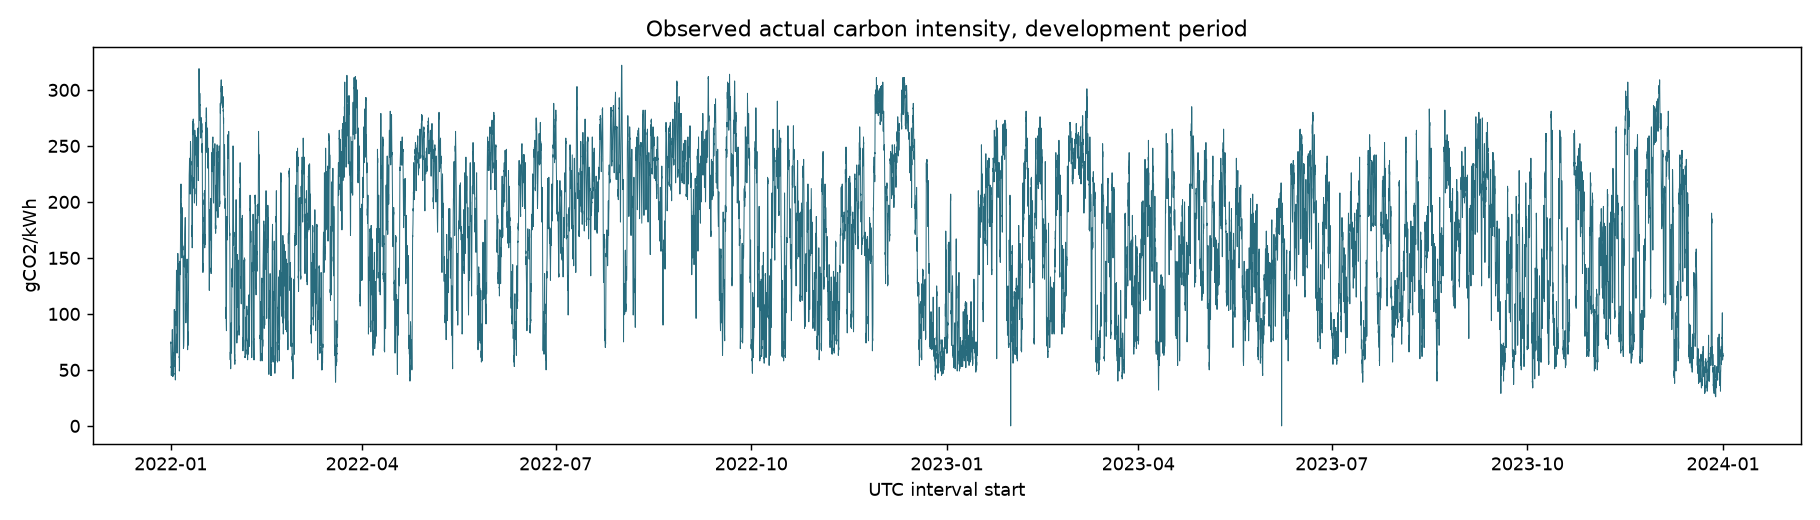

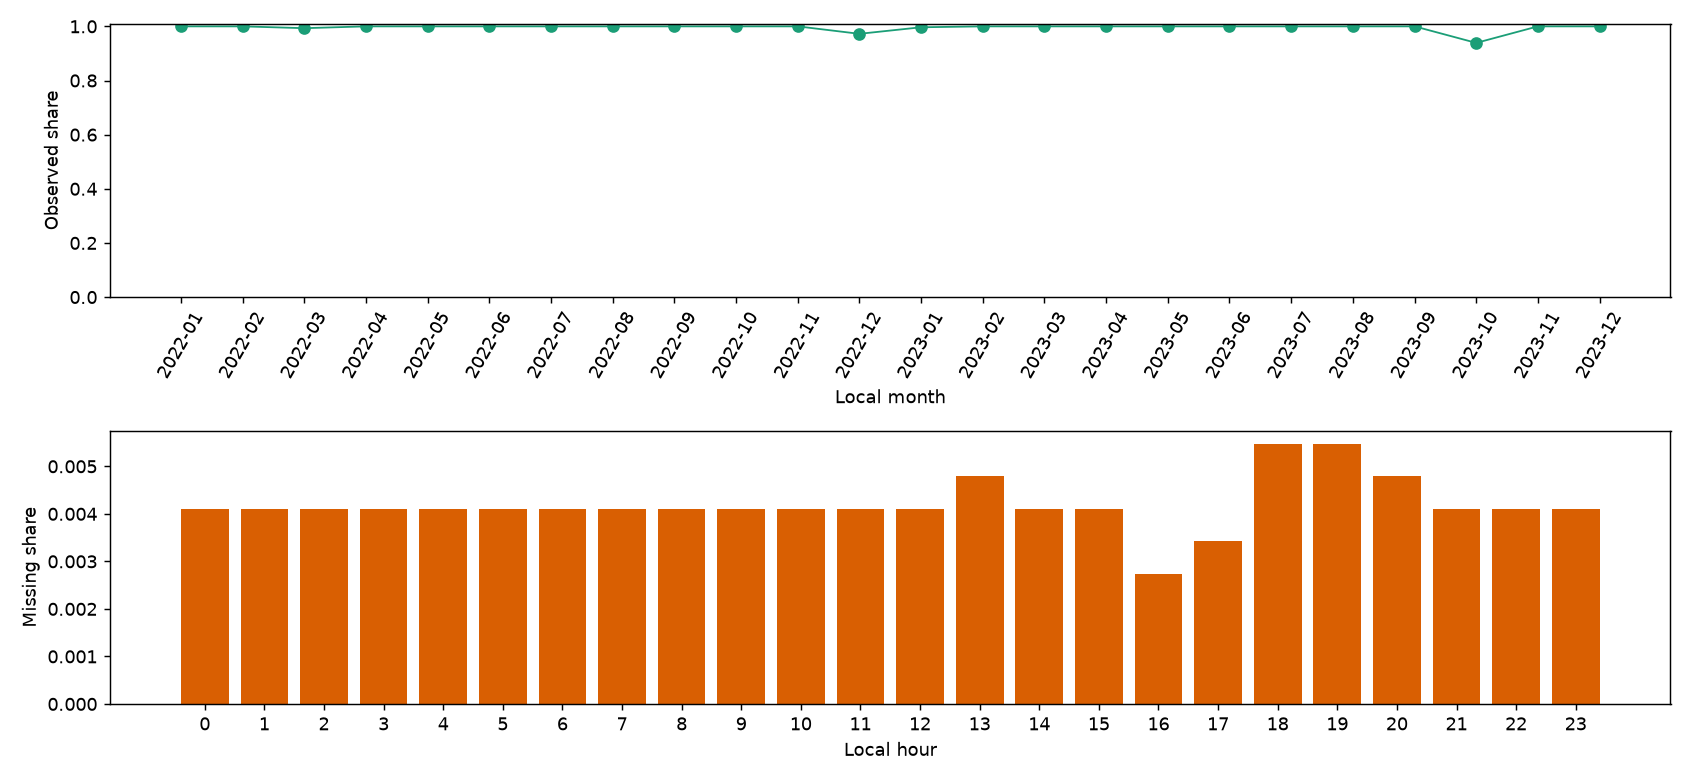

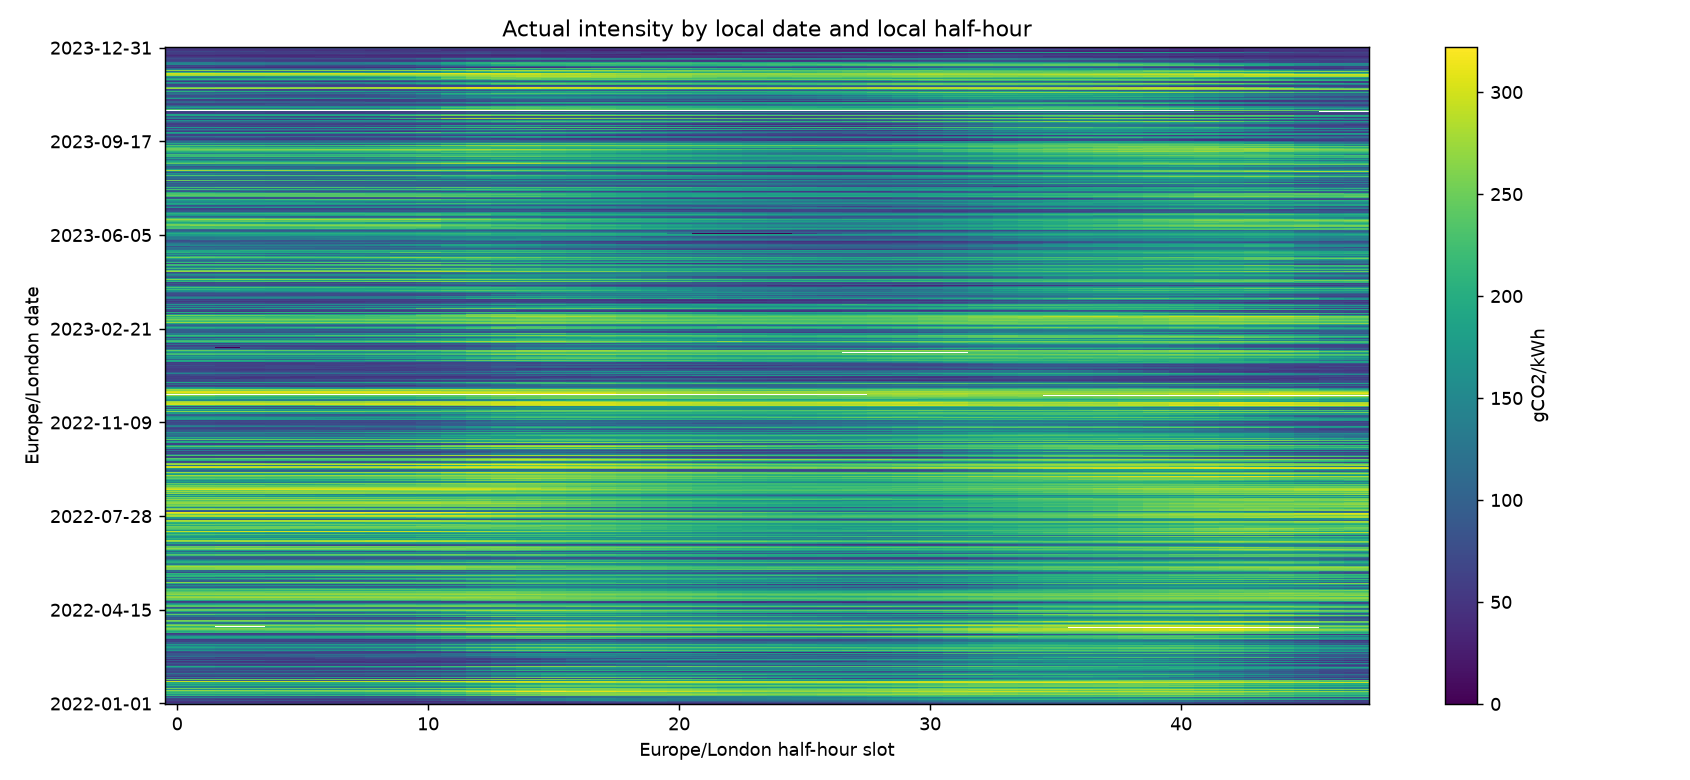

In [3]:
quality = json.loads((ROOT / 'artifacts/data/quality.json').read_text(encoding='utf-8'))
display(pd.Series(quality, name='value').to_frame())
diagnostics = json.loads((ROOT / 'artifacts/diagnostics/diagnostics.json').read_text(encoding='utf-8'))
display(pd.DataFrame([diagnostics.get('development_opportunity', {})]))
for name in ('series.png', 'missingness.png', 'daily_slot_heatmap.png'):
    path = ROOT / 'artifacts/diagnostics/figures' / name
    if path.is_file():
        display(Image(filename=str(path)))

## 3. ADF, transformations, differencing, decomposition, and ACF/PACF

ADF tests the unit-root null under the recorded deterministic regression; its augmentation lag is not an AR model order. KPSS tests a stationarity null. The recorded AIC and BIC autolag choices use a 48-slot cap on contiguous development segments. Neither test proves stable forecasts across years.

Recorded level ADF p-values range from 6.769e-21 to 3.5813e-12. Level KPSS p-values are 0.08477, 0.08268. KPSS values at 0.1 or 0.01 are lookup-table bounds, not exact tail probabilities. Read each against its specified regression, sample period, and lag cap. These tests do not establish stability across years or prove white noise.

Identity and log1p representations compete on chronological validation loss, not incompatible absolute likelihoods. Inverting a Gaussian log1p forecast uses exp(mu + variance/2) - 1 for its conditional mean; exp(mu) - 1 is a median. Statsmodels state-space integration restores differenced level paths. First, seasonal, and combined differences are diagnostics even when omitted from the selected forecast. Box-Cox requires strictly positive inputs and is recorded as inappropriate where zero targets occur.

STL with period 48 is a descriptive centered decomposition, not a real-time predictor. ACF/PACF guide a bounded catalogue, while held-out errors decide between representations. Zero-valued carbon remains observed data.

adf.csv


,variant,regression,autolag,status,sample_n,maxlag,selected_lag,test_statistic,p_value,used_n,critical_1pct,critical_5pct,critical_10pct,ic_best,sample_start_utc,sample_end_exclusive_utc
0,levels_identity,c,AIC,ok,12828,48,48,-11.423891,6.769007e-21,12779,-3.430862,-2.861766,-2.566890,82155.954989,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
1,levels_identity,c,BIC,ok,12828,48,48,-11.423891,6.769007e-21,12779,-3.430862,-2.861766,-2.566890,82528.732913,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
2,levels_identity,ct,AIC,ok,12828,48,48,-11.509186,2.595432e-18,12779,-3.959479,-3.410834,-3.127252,82155.996956,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
3,levels_identity,ct,BIC,ok,12828,48,48,-11.509186,2.595432e-18,12779,-3.959479,-3.410834,-3.127252,82536.230438,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
4,levels_log1p,c,AIC,ok,12828,48,48,-8.499684,1.248059e-13,12779,-3.430862,-2.861766,-2.566890,-24422.886359,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
5,levels_log1p,c,BIC,ok,12828,48,48,-8.499684,1.248059e-13,12779,-3.430862,-2.861766,-2.566890,-24050.108435,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
6,levels_log1p,ct,AIC,ok,12828,48,48,-8.563751,3.581253e-12,12779,-3.959479,-3.410834,-3.127252,-24421.984108,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
7,levels_log1p,ct,BIC,ok,12828,48,48,-8.563751,3.581253e-12,12779,-3.959479,-3.410834,-3.127252,-24041.750625,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
8,first_difference_identity,c,AIC,ok,12827,48,48,-14.040515,3.309898e-26,12778,-3.430862,-2.861766,-2.566890,82269.354939,2023-01-26 16:30:00+00:00,2023-10-20 22:00:00+00:00
9,first_difference_identity,c,BIC,ok,12827,48,48,-14.040515,3.309898e-26,12778,-3.430862,-2.861766,-2.566890,82642.128950,2023-01-26 16:30:00+00:00,2023-10-20 22:00:00+00:00


kpss.csv


,variant,regression,status,sample_n,selected_lag,test_statistic,p_value,critical_10pct,critical_5pct,critical_2_5pct,critical_1pct,sample_start_utc,sample_end_exclusive_utc
0,levels_identity,c,ok,12828,68,0.382333,0.08477,0.347,0.463,0.574,0.739,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
1,levels_log1p,c,ok,12828,67,0.387183,0.08268,0.347,0.463,0.574,0.739,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
2,first_difference_identity,c,ok,12827,29,0.003362,0.10000,0.347,0.463,0.574,0.739,2023-01-26 16:30:00+00:00,2023-10-20 22:00:00+00:00
3,first_difference_log1p,c,ok,12827,23,0.002806,0.10000,0.347,0.463,0.574,0.739,2023-01-26 16:30:00+00:00,2023-10-20 22:00:00+00:00
4,seasonal_difference_48_identity,c,ok,12780,68,0.006811,0.10000,0.347,0.463,0.574,0.739,2023-01-27 16:00:00+00:00,2023-10-20 22:00:00+00:00
5,seasonal_difference_48_log1p,c,ok,12780,67,0.006415,0.10000,0.347,0.463,0.574,0.739,2023-01-27 16:00:00+00:00,2023-10-20 22:00:00+00:00
6,combined_difference_teaching_identity,c,ok,12779,32,0.001629,0.10000,0.347,0.463,0.574,0.739,2023-01-27 16:30:00+00:00,2023-10-20 22:00:00+00:00
7,combined_difference_teaching_log1p,c,ok,12779,60,0.002033,0.10000,0.347,0.463,0.574,0.739,2023-01-27 16:30:00+00:00,2023-10-20 22:00:00+00:00


distribution.csv


,statistic,value
0,count,34893.000000
1,missing,147.000000
2,zeros,5.000000
3,mean,167.361706
4,std,65.694454
5,skew,-0.086697
6,kurtosis,-1.022971
7,iqr_lower_extreme_count,0.000000
8,iqr_upper_extreme_count,0.000000
9,q000,0.000000


stl48_components.csv


,interval_start_utc,actual_short_gap_adjusted,trend,seasonal_48,remainder
0,2023-01-26 16:00:00+00:00,228.0,228.011688,0.111202,-0.122889
1,2023-01-26 16:30:00+00:00,229.0,228.112106,-0.588674,1.476568
2,2023-01-26 17:00:00+00:00,229.0,228.213650,-2.860592,3.646942
3,2023-01-26 17:30:00+00:00,231.0,228.316370,-1.154123,3.837753
4,2023-01-26 18:00:00+00:00,234.0,228.420305,2.861953,2.717741
5,2023-01-26 18:30:00+00:00,238.0,228.525488,6.274149,3.200363
6,2023-01-26 19:00:00+00:00,239.0,228.631942,8.773898,1.594161
7,2023-01-26 19:30:00+00:00,238.0,228.739686,8.272133,0.988181
8,2023-01-26 20:00:00+00:00,241.0,228.848735,14.867886,-2.716621
9,2023-01-26 20:30:00+00:00,239.0,228.959103,12.016593,-1.975696


acf_pacf.csv


,variant,lag,acf,pacf,status,sample_n
0,levels_identity,0,1.000000,1.000000,ok,12828
1,levels_identity,1,0.991744,0.991744,ok,12828
2,levels_identity,2,0.975806,-0.471314,ok,12828
3,levels_identity,3,0.954179,-0.176850,ok,12828
4,levels_identity,4,0.928733,-0.044325,ok,12828
5,levels_identity,5,0.901261,0.024809,ok,12828
6,levels_identity,6,0.872632,-0.003244,ok,12828
7,levels_identity,7,0.844071,0.040845,ok,12828
8,levels_identity,8,0.815890,-0.002710,ok,12828
9,levels_identity,9,0.789072,0.055422,ok,12828


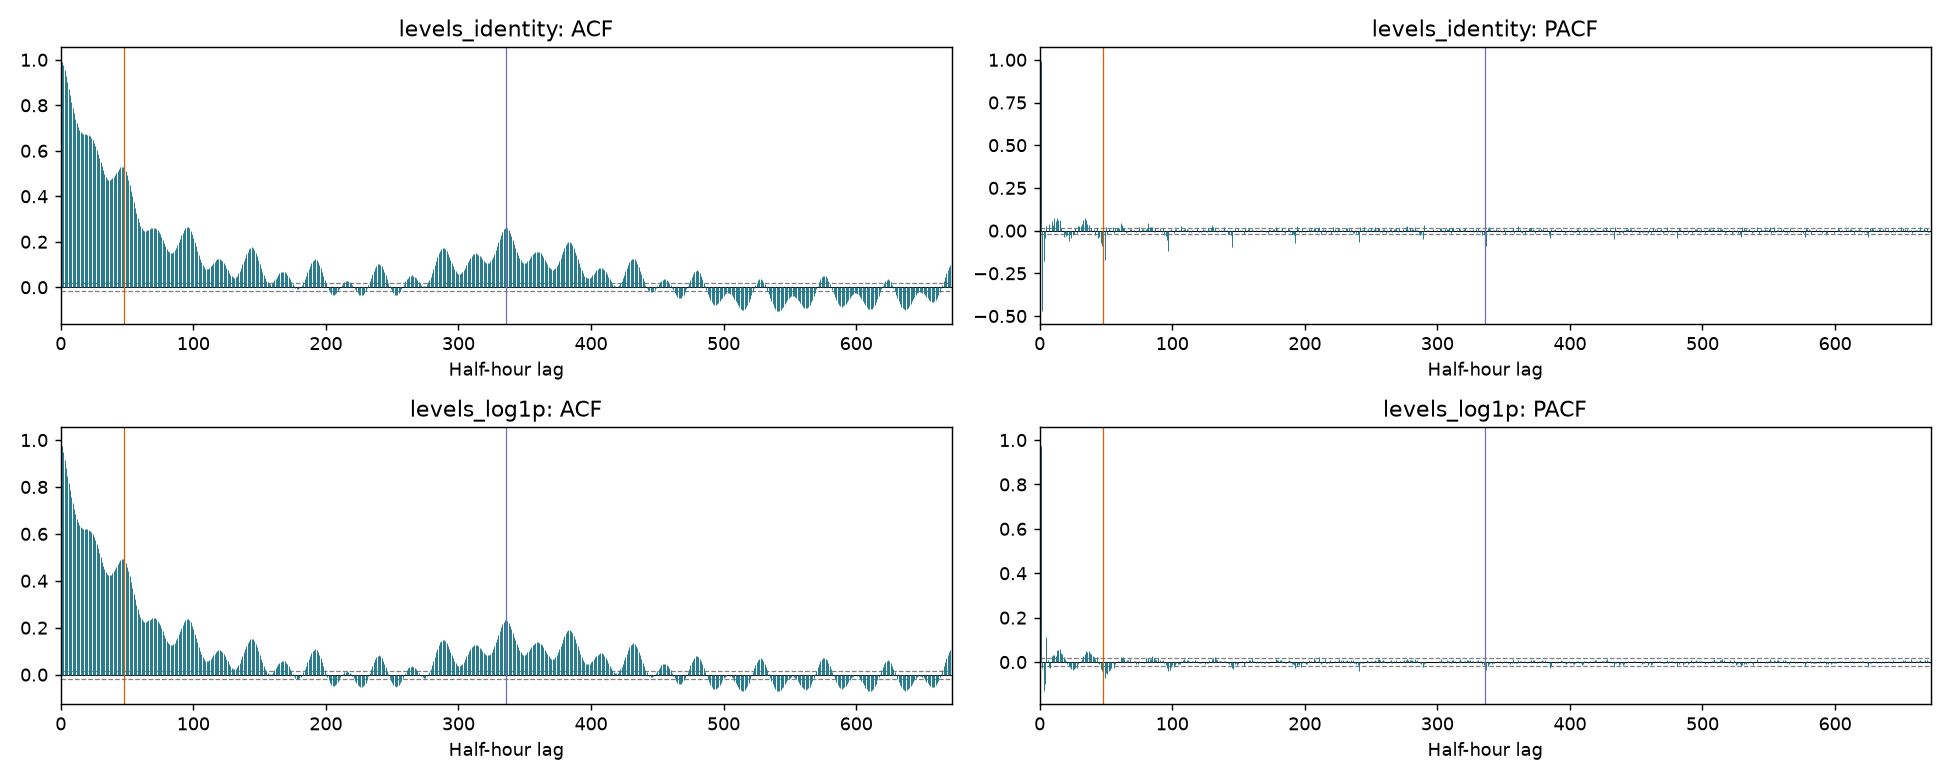

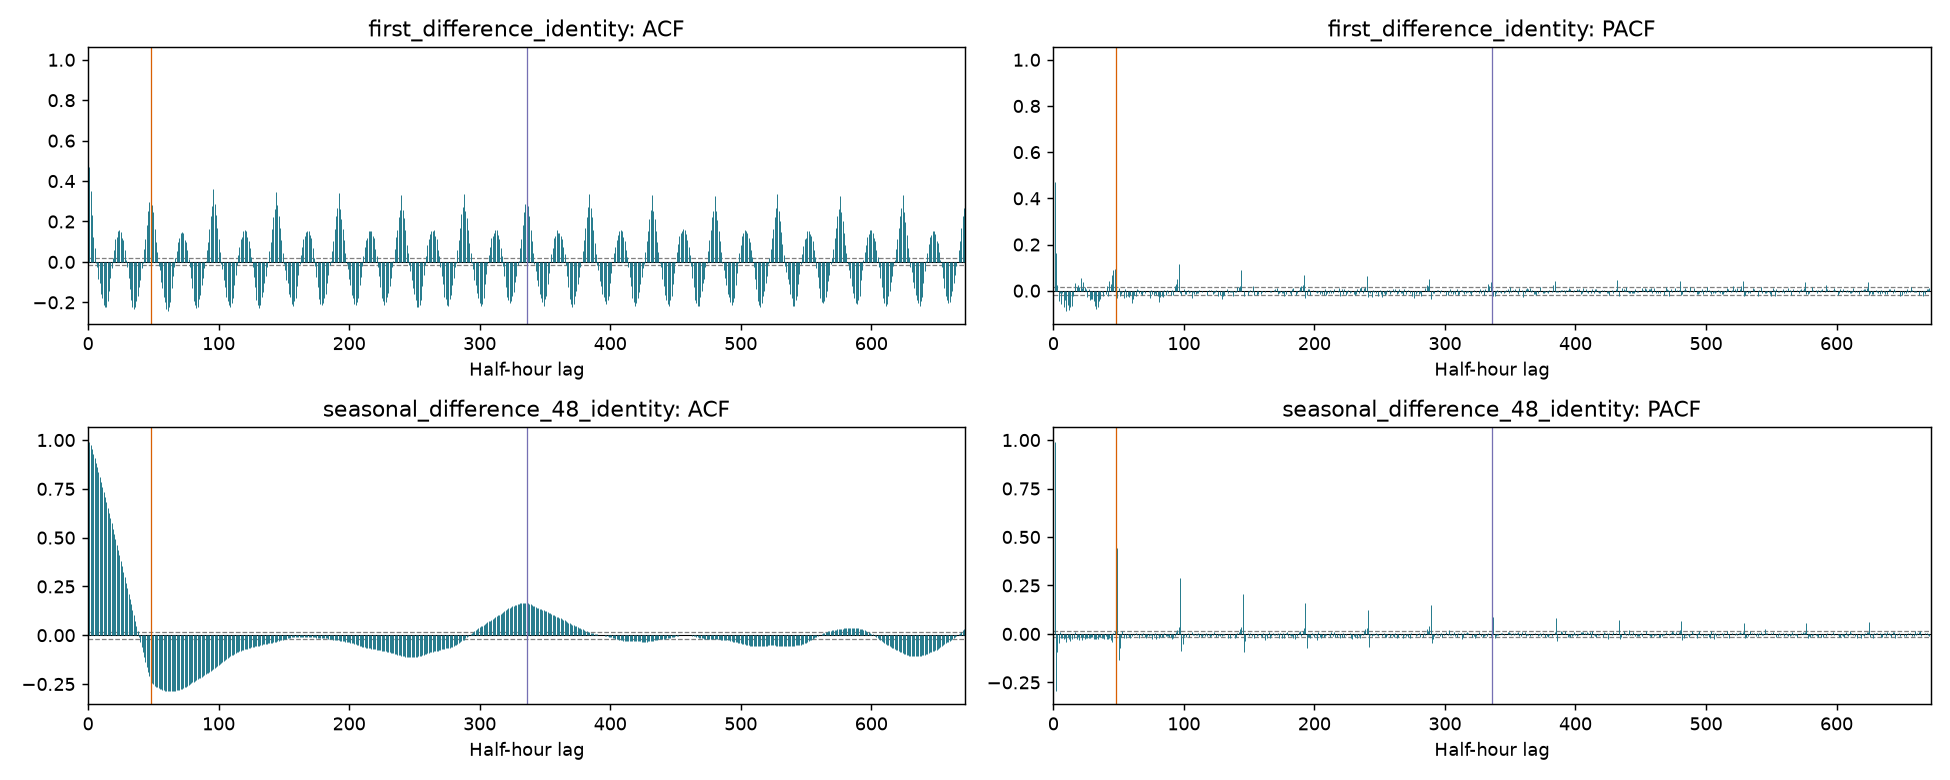

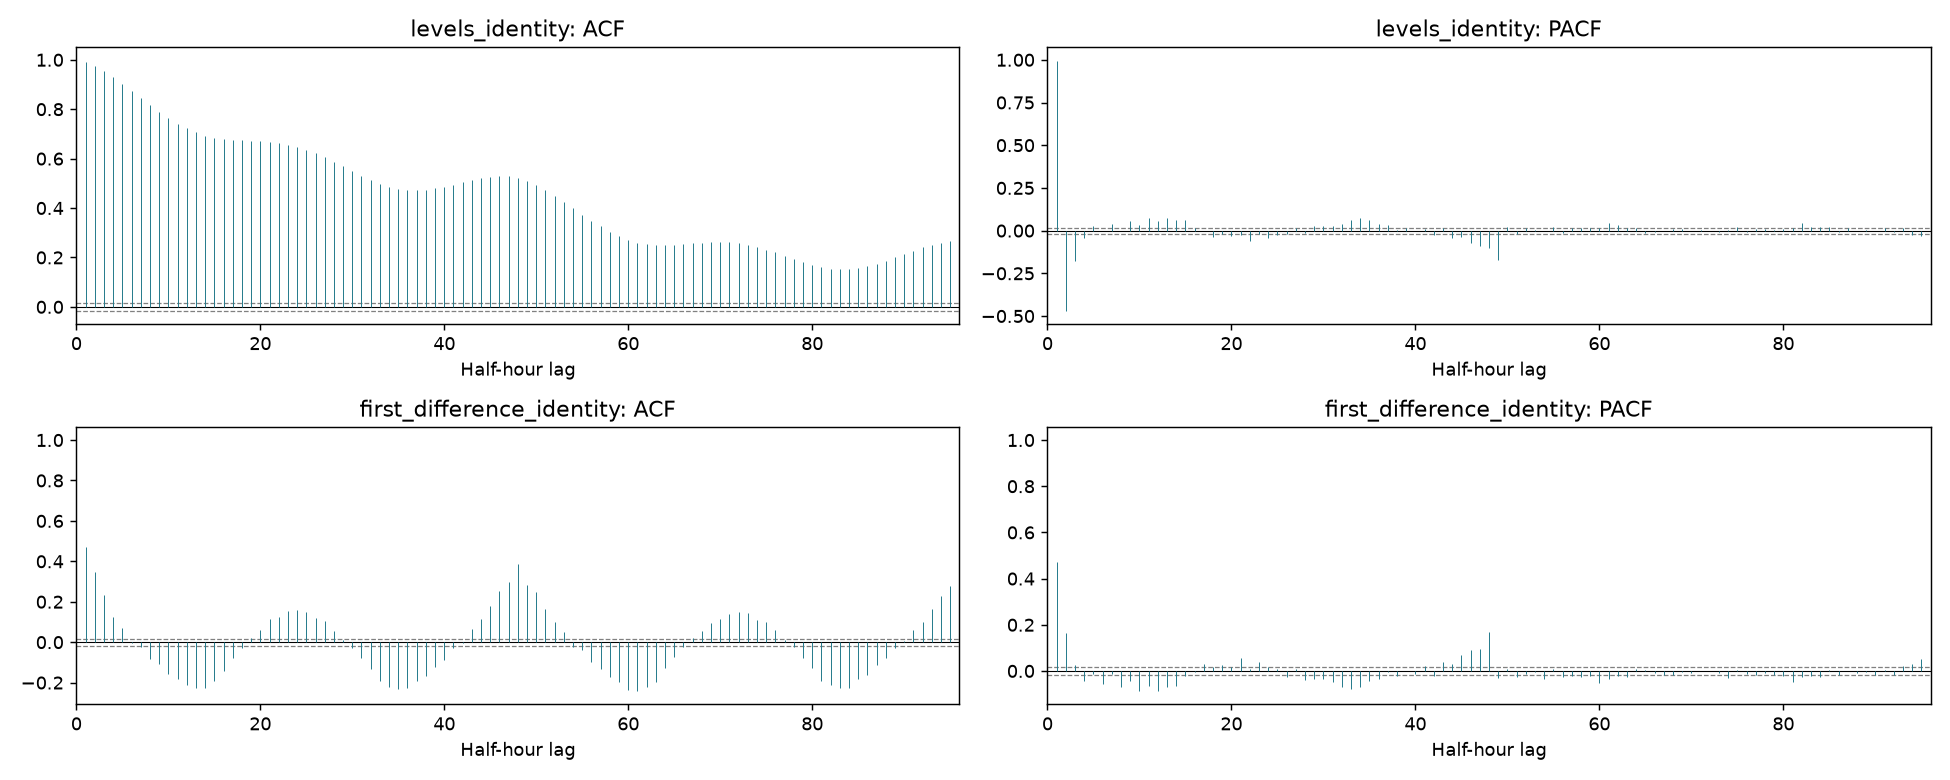

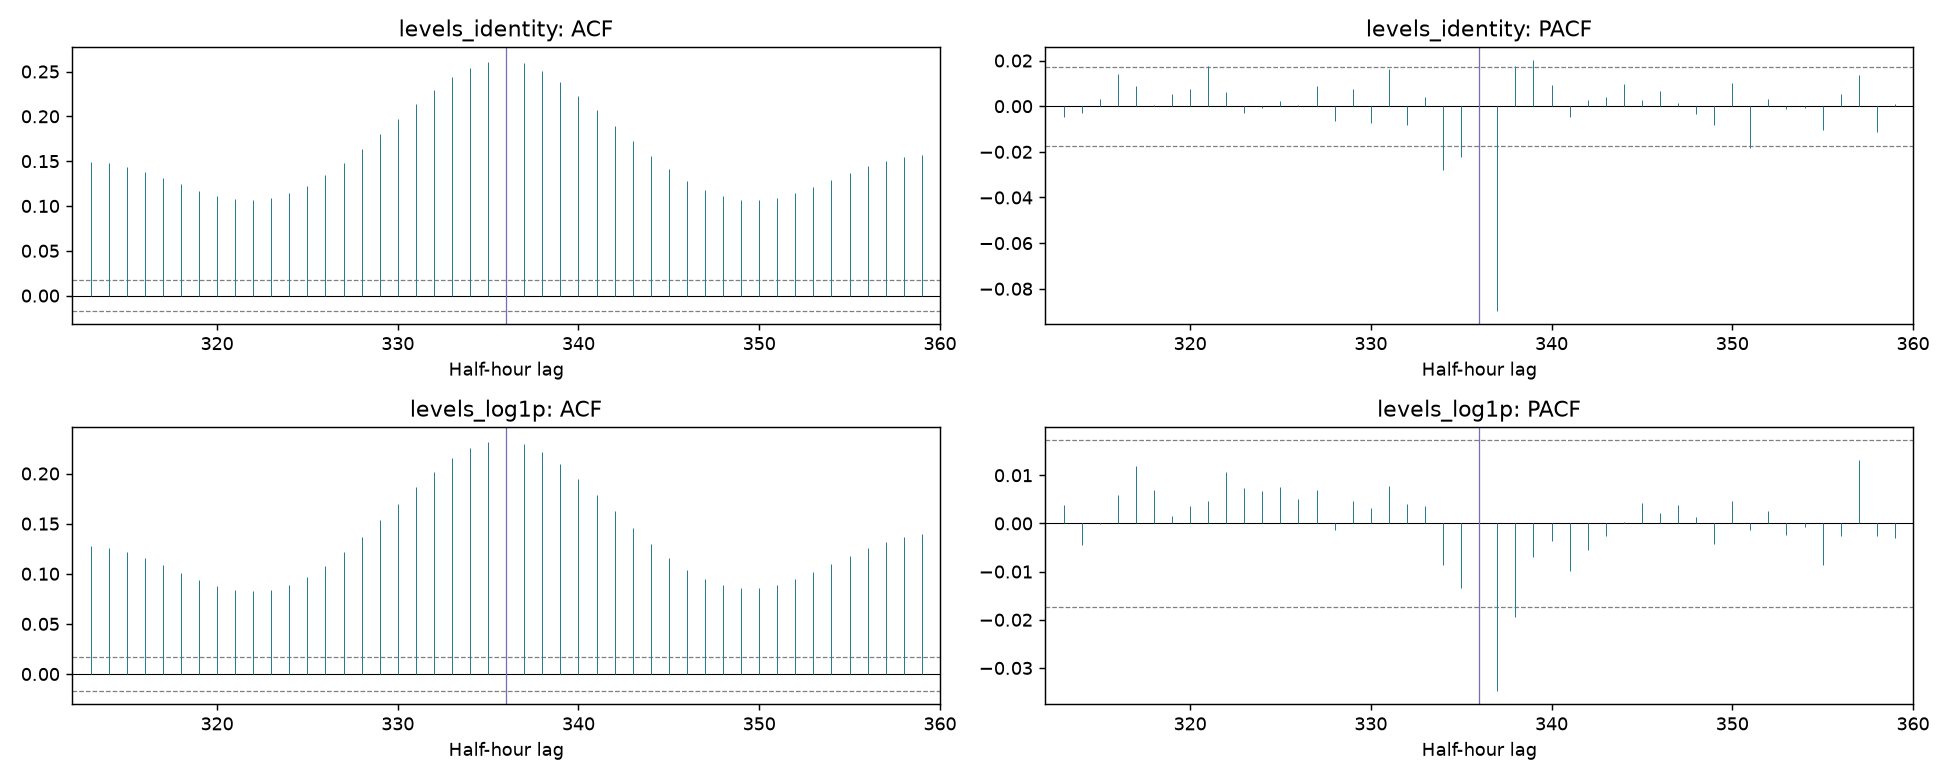

In [4]:
for name in ('adf.csv', 'kpss.csv', 'distribution.csv', 'stl48_components.csv', 'acf_pacf.csv'):
    path = ROOT / 'artifacts/diagnostics' / name
    if path.is_file():
        print(name)
        display(pd.read_csv(path).head(20))
for name in ('acf_pacf_levels.png', 'acf_pacf_differences.png', 'acf_pacf_daily.png', 'acf_pacf_weekly.png'):
    path = ROOT / 'artifacts/diagnostics/figures' / name
    if path.is_file():
        display(Image(filename=str(path)))

## 4. AR, MA, ARMA, ARIMA, and SARIMA

The package owns the model definitions and fitting logic. This notebook reads the recorded forecasts and diagnostics. It does not fit a second copy of any model.

### Model equations

These schematic forms use B for the lag operator and epsilon[t] for an innovation:

```text
AR(p):       y[t] = c + phi_1*y[t-1] + ... + phi_p*y[t-p] + epsilon[t]
MA(q):       y[t] = mu + epsilon[t] + theta_1*epsilon[t-1] + ... + theta_q*epsilon[t-q]
ARMA(p,q):   combine AR(p) dependence in y with MA(q) dependence in epsilon
ARIMA(p,d,q): phi(B)*(1-B)^d*y[t] = c + theta(B)*epsilon[t]
SARIMA:      Phi(B^48)*phi(B)*(1-B)^d*(1-B^48)^D*y[t] = Theta(B^48)*theta(B)*epsilon[t]
```

AR, MA, and ARMA are the d=0 cases of ARIMA. The seasonal period is 48 half-hour slots. These equations describe the model families; fitted parameter values below come only from the stored validation residual-fit artifacts.

In [5]:
parameter_files = sorted(VALIDATION_RESIDUALS.glob('model_*_parameters.json'))
fitted_examples = []
for path in parameter_files:
    record = json.loads(path.read_text(encoding='utf-8'))
    spec = record.get('spec', {})
    names = record.get('parameter_names', [])
    values = record.get('parameters', [])
    fitted_examples.append({
        'file': path.name,
        'model': spec.get('name'),
        'family': spec.get('family'),
        'order': spec.get('order'),
        'seasonal_order': spec.get('seasonal_order'),
        'transform': spec.get('transform'),
        'training_cutoff': record.get('training_cutoff'),
        'parameters': dict(zip(names, values)) if len(names) == len(values) else values,
    })
if fitted_examples:
    display(pd.DataFrame(fitted_examples))
else:
    print('No validation residual-fit parameter files were recorded.')
print('Configured transforms:', CONFIG.get('forecast', {}).get('transforms'))
print('Seasonal period:', 48, 'half-hour slots')

,file,model,family,order,seasonal_order,transform,training_cutoff,parameters
0,model_00_parameters.json,"AR(7,0,0)",AR,"[7, 0, 0]","[0, 0, 0, 0]",identity,2024-11-30 23:00:00+00:00,"{'intercept': 1.7237582631118111, 'ar.L1': 1.5..."
1,model_01_parameters.json,"MA(0,0,8)[log1p]",MA,"[0, 0, 8]","[0, 0, 0, 0]",log1p,2024-11-30 23:00:00+00:00,"{'intercept': 4.709971719514808, 'ma.L1': 1.63..."
2,model_02_parameters.json,"ARMA(3,0,2)",ARMA,"[3, 0, 2]","[0, 0, 0, 0]",identity,2024-11-30 23:00:00+00:00,"{'intercept': 0.06634391985786915, 'ar.L1': 2...."
3,model_03_parameters.json,"ARIMA(3,1,3)",ARIMA,"[3, 1, 3]","[0, 0, 0, 0]",identity,2024-11-30 23:00:00+00:00,"{'ar.L1': 0.8254031426413928, 'ar.L2': 0.83979..."
4,model_04_parameters.json,"SARIMA(1,0,1)x(1,0,0,48)",SARIMA,"[1, 0, 1]","[1, 0, 0, 48]",identity,2024-11-30 23:00:00+00:00,"{'intercept': 0.9743660211529825, 'ar.L1': 0.9..."


Configured transforms: ['identity', 'log1p']
Seasonal period: 48 half-hour slots


## 5. Lag selection, information criteria, convergence, and residual checks

Residual tests describe representative validation fits on contiguous observed innovation segments. They are diagnostics, not a substitute for chronological forecast scores.

,name,family,order,seasonal_order,transform,anchor,training_start,training_cutoff,observed_n,filled_n,...,aicc,aicc_rank,bic_rank,d_value,D_value,period,median_aicc_rank,median_bic_rank,converged_anchors,selected
0,"AR(1,0,0)",AR,"[1, 0, 0]","[0, 0, 0, 0]",identity,2024-01-01T00:00:00+00:00,2023-07-05T00:00:00+00:00,2023-12-31T23:00:00+00:00,8548,0,...,57502.694126,8.0,8.0,0,0,0,8.0,8.0,12,False
1,"AR(2,0,0)",AR,"[2, 0, 0]","[0, 0, 0, 0]",identity,2024-01-01T00:00:00+00:00,2023-07-05T00:00:00+00:00,2023-12-31T23:00:00+00:00,8548,0,...,54276.652490,7.0,7.0,0,0,0,7.0,7.0,12,False
2,"AR(3,0,0)",AR,"[3, 0, 0]","[0, 0, 0, 0]",identity,2024-01-01T00:00:00+00:00,2023-07-05T00:00:00+00:00,2023-12-31T23:00:00+00:00,8548,0,...,54029.087751,3.0,1.0,0,0,0,5.0,2.5,12,False
3,"AR(4,0,0)",AR,"[4, 0, 0]","[0, 0, 0, 0]",identity,2024-01-01T00:00:00+00:00,2023-07-05T00:00:00+00:00,2023-12-31T23:00:00+00:00,8548,0,...,54030.270920,4.0,4.0,0,0,0,5.0,3.5,12,False
4,"AR(5,0,0)",AR,"[5, 0, 0]","[0, 0, 0, 0]",identity,2024-01-01T00:00:00+00:00,2023-07-05T00:00:00+00:00,2023-12-31T23:00:00+00:00,8548,0,...,54030.330305,5.0,5.0,0,0,0,3.5,5.0,12,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1075,"ARIMA(3,1,3)[log1p]",ARIMA,"[3, 1, 3]","[0, 0, 0, 0]",log1p,2024-12-01T00:00:00+00:00,2024-06-04T00:00:00+00:00,2024-11-30T23:00:00+00:00,8608,0,...,-25461.253461,1.0,2.0,1,0,0,NaN,NaN,7,False
1076,"SARIMA(1,0,0)x(1,0,0,48)[log1p]",SARIMA,"[1, 0, 0]","[1, 0, 0, 48]",log1p,2024-12-01T00:00:00+00:00,2024-06-04T00:00:00+00:00,2024-11-30T23:00:00+00:00,8608,0,...,-20953.356556,3.0,3.0,0,0,48,2.5,2.5,12,False
1077,"SARIMA(0,0,1)x(0,0,1,48)[log1p]",SARIMA,"[0, 0, 1]","[0, 0, 1, 48]",log1p,2024-12-01T00:00:00+00:00,2024-06-04T00:00:00+00:00,2024-11-30T23:00:00+00:00,8608,0,...,-1534.215329,4.0,4.0,0,0,48,4.0,4.0,12,False
1078,"SARIMA(1,0,1)x(1,0,0,48)[log1p]",SARIMA,"[1, 0, 1]","[1, 0, 0, 48]",log1p,2024-12-01T00:00:00+00:00,2024-06-04T00:00:00+00:00,2024-11-30T23:00:00+00:00,8608,0,...,-21770.686983,2.0,2.0,0,0,48,1.0,1.0,10,True


,variant,regression,autolag,status,sample_n,maxlag,selected_lag,test_statistic,p_value,used_n,critical_1pct,critical_5pct,critical_10pct,ic_best,sample_start_utc,sample_end_exclusive_utc
0,levels_identity,c,AIC,ok,12828,48,48,-11.423891,6.769007e-21,12779,-3.430862,-2.861766,-2.566890,82155.954989,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
1,levels_identity,c,BIC,ok,12828,48,48,-11.423891,6.769007e-21,12779,-3.430862,-2.861766,-2.566890,82528.732913,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
2,levels_identity,ct,AIC,ok,12828,48,48,-11.509186,2.595432e-18,12779,-3.959479,-3.410834,-3.127252,82155.996956,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
3,levels_identity,ct,BIC,ok,12828,48,48,-11.509186,2.595432e-18,12779,-3.959479,-3.410834,-3.127252,82536.230438,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
4,levels_log1p,c,AIC,ok,12828,48,48,-8.499684,1.248059e-13,12779,-3.430862,-2.861766,-2.566890,-24422.886359,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
5,levels_log1p,c,BIC,ok,12828,48,48,-8.499684,1.248059e-13,12779,-3.430862,-2.861766,-2.566890,-24050.108435,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
6,levels_log1p,ct,AIC,ok,12828,48,48,-8.563751,3.581253e-12,12779,-3.959479,-3.410834,-3.127252,-24421.984108,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
7,levels_log1p,ct,BIC,ok,12828,48,48,-8.563751,3.581253e-12,12779,-3.959479,-3.410834,-3.127252,-24041.750625,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
8,first_difference_identity,c,AIC,ok,12827,48,48,-14.040515,3.309898e-26,12778,-3.430862,-2.861766,-2.566890,82269.354939,2023-01-26 16:30:00+00:00,2023-10-20 22:00:00+00:00
9,first_difference_identity,c,BIC,ok,12827,48,48,-14.040515,3.309898e-26,12778,-3.430862,-2.861766,-2.566890,82642.128950,2023-01-26 16:30:00+00:00,2023-10-20 22:00:00+00:00


,variant,regression,status,sample_n,selected_lag,test_statistic,p_value,critical_10pct,critical_5pct,critical_2_5pct,critical_1pct,sample_start_utc,sample_end_exclusive_utc
0,levels_identity,c,ok,12828,68,0.382333,0.08477,0.347,0.463,0.574,0.739,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
1,levels_log1p,c,ok,12828,67,0.387183,0.08268,0.347,0.463,0.574,0.739,2023-01-26 16:00:00+00:00,2023-10-20 22:00:00+00:00
2,first_difference_identity,c,ok,12827,29,0.003362,0.10000,0.347,0.463,0.574,0.739,2023-01-26 16:30:00+00:00,2023-10-20 22:00:00+00:00
3,first_difference_log1p,c,ok,12827,23,0.002806,0.10000,0.347,0.463,0.574,0.739,2023-01-26 16:30:00+00:00,2023-10-20 22:00:00+00:00
4,seasonal_difference_48_identity,c,ok,12780,68,0.006811,0.10000,0.347,0.463,0.574,0.739,2023-01-27 16:00:00+00:00,2023-10-20 22:00:00+00:00
5,seasonal_difference_48_log1p,c,ok,12780,67,0.006415,0.10000,0.347,0.463,0.574,0.739,2023-01-27 16:00:00+00:00,2023-10-20 22:00:00+00:00
6,combined_difference_teaching_identity,c,ok,12779,32,0.001629,0.10000,0.347,0.463,0.574,0.739,2023-01-27 16:30:00+00:00,2023-10-20 22:00:00+00:00
7,combined_difference_teaching_log1p,c,ok,12779,60,0.002033,0.10000,0.347,0.463,0.574,0.739,2023-01-27 16:30:00+00:00,2023-10-20 22:00:00+00:00


,lag,lb_stat,lb_pvalue,model_id,n_contiguous
0,12,56.228393,7.292402e-11,"AR(7,0,0)",8226
1,48,1543.580198,2.513371e-297,"AR(7,0,0)",8226
2,96,2745.255341,0.000000e+00,"AR(7,0,0)",8226
3,12,5207.724152,0.000000e+00,"MA(0,0,8)[log1p]",8226
4,48,12730.562845,0.000000e+00,"MA(0,0,8)[log1p]",8226
5,96,16368.089336,0.000000e+00,"MA(0,0,8)[log1p]",8226
6,12,60.219170,1.364841e-10,"ARMA(3,0,2)",8226
7,48,1202.669792,6.107271e-224,"ARMA(3,0,2)",8226
8,96,2125.403682,0.000000e+00,"ARMA(3,0,2)",8226
9,12,46.478676,2.377026e-08,"ARIMA(3,1,3)",8226


model_00_acf_pacf.csv


...

,lag,acf,pacf
0,0,1.000000,1.000000
1,1,0.002647,0.002647
2,2,0.001326,0.001319
3,3,-0.012625,-0.012632
4,4,-0.021535,-0.021473
5,5,0.012575,0.012725
6,6,-0.013585,-0.013760
7,7,0.033952,0.033481
8,8,0.016690,0.016412
9,9,0.036095,0.036209


model_03_acf_pacf.csv


,lag,acf,pacf
0,0,1.000000,1.000000
1,1,-0.001819,-0.001819
2,2,0.019539,0.019536
3,3,-0.025510,-0.025450
4,4,-0.009365,-0.009835
5,5,-0.000872,0.000096
6,6,-0.003257,-0.003535
7,7,0.022670,0.022210
8,8,0.026085,0.026217
9,9,0.027484,0.026575


model_04_acf_pacf.csv


,lag,acf,pacf
0,0,1.000000,1.000000
1,1,0.107765,0.107765
2,2,0.308192,0.300064
3,3,0.124255,0.076354
4,4,0.089343,-0.018021
5,5,0.057750,-0.006907
6,6,-0.004500,-0.042625
7,7,0.003565,-0.015981
8,8,-0.037276,-0.029151
9,9,-0.035342,-0.025139


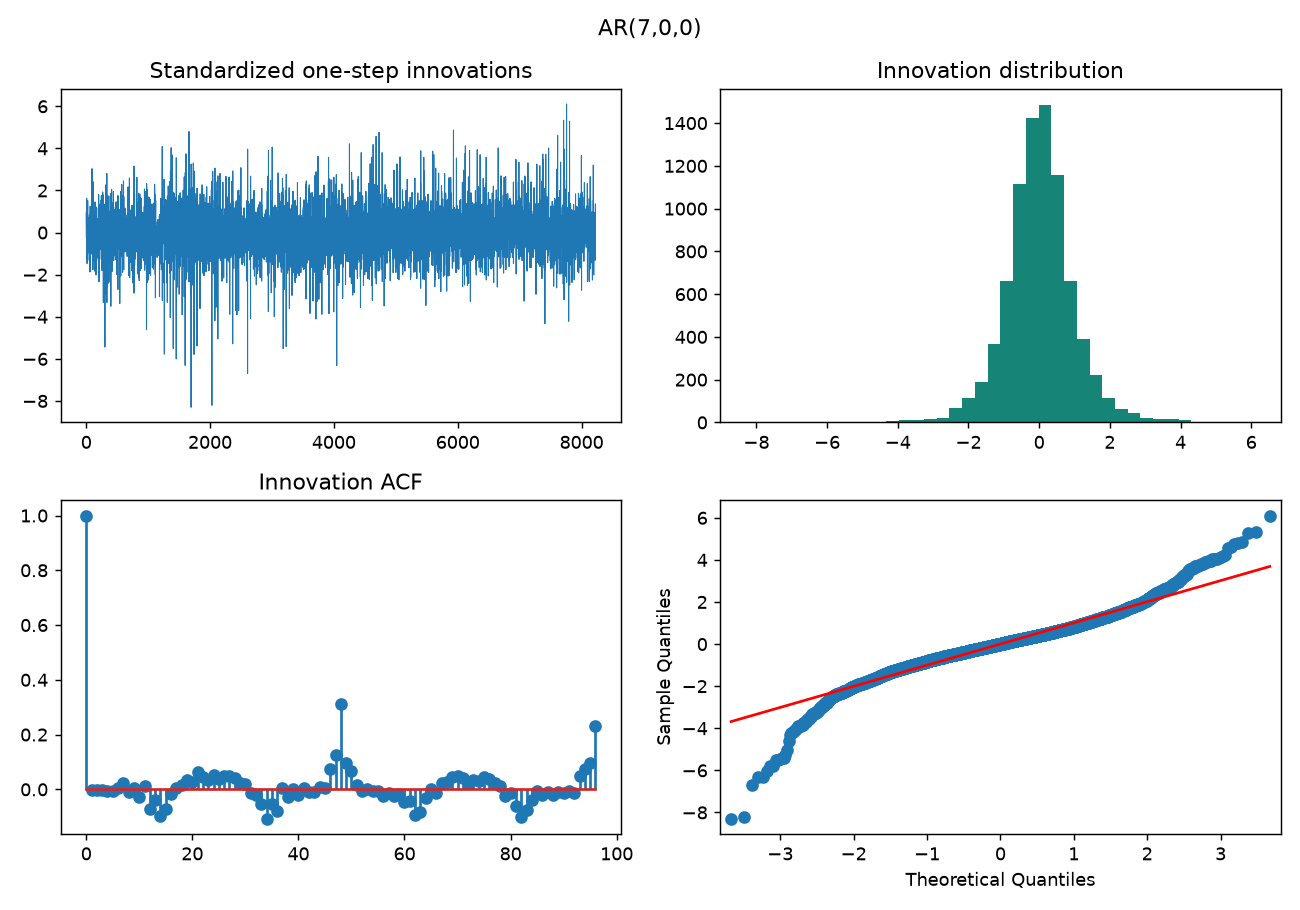

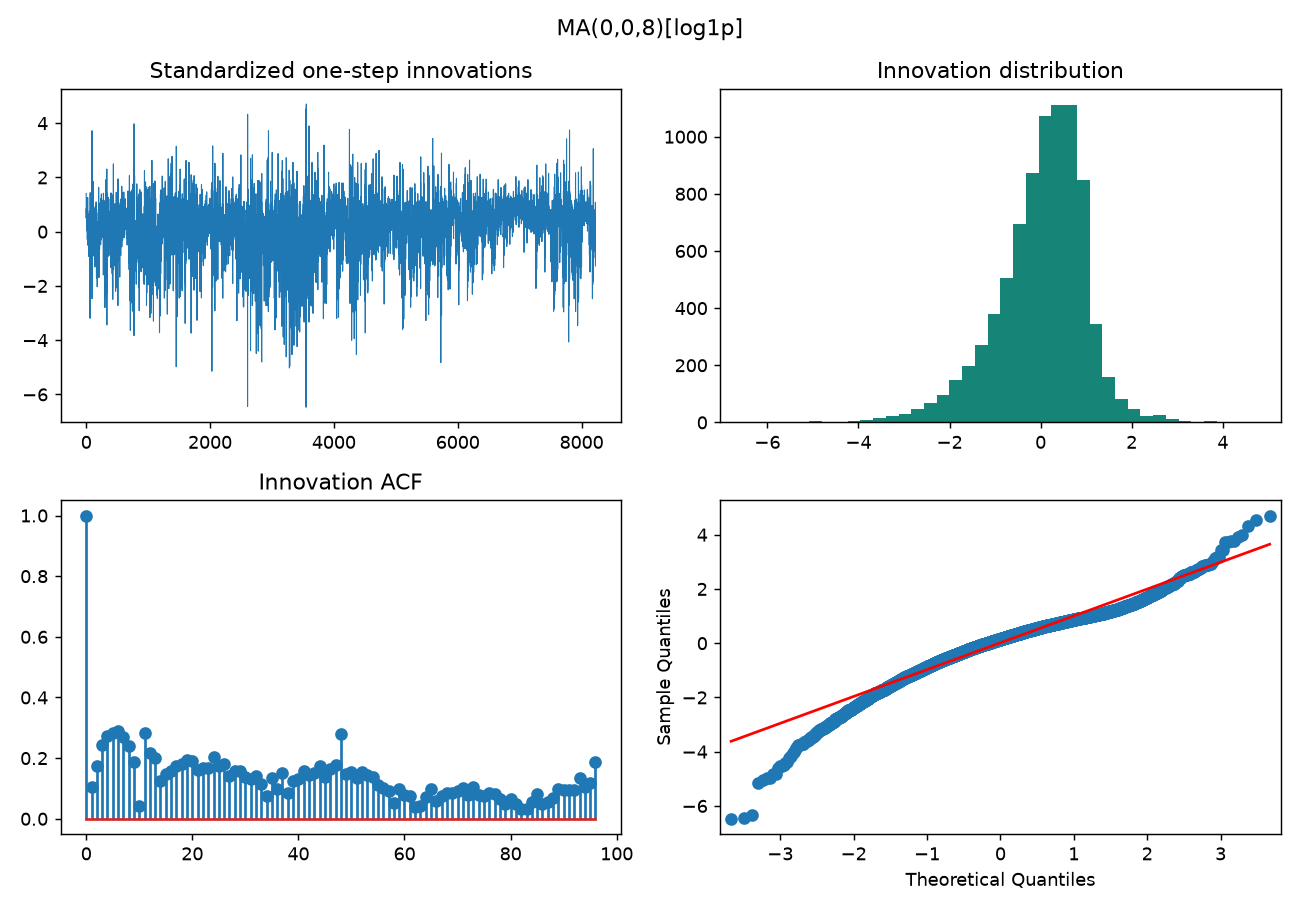

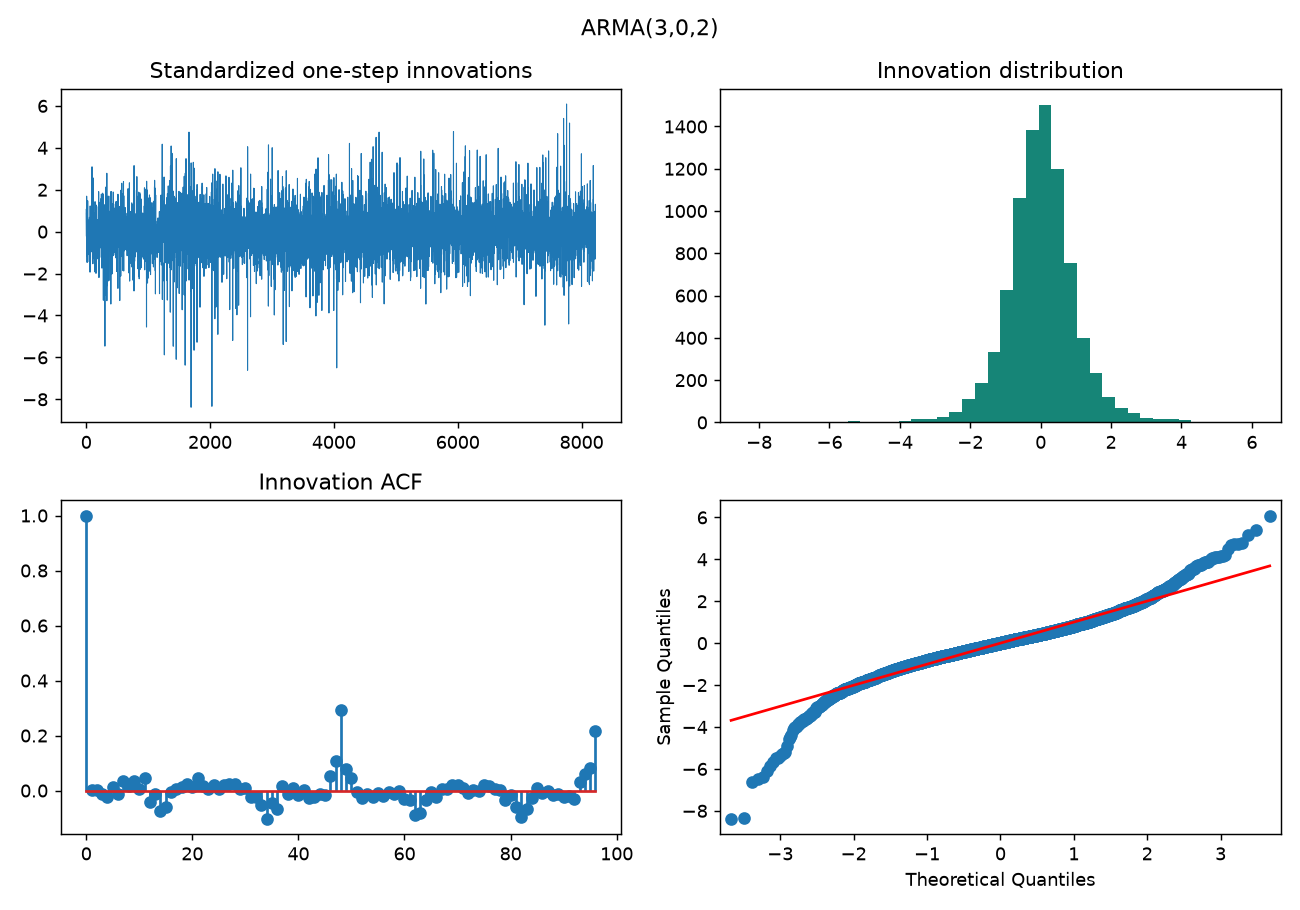

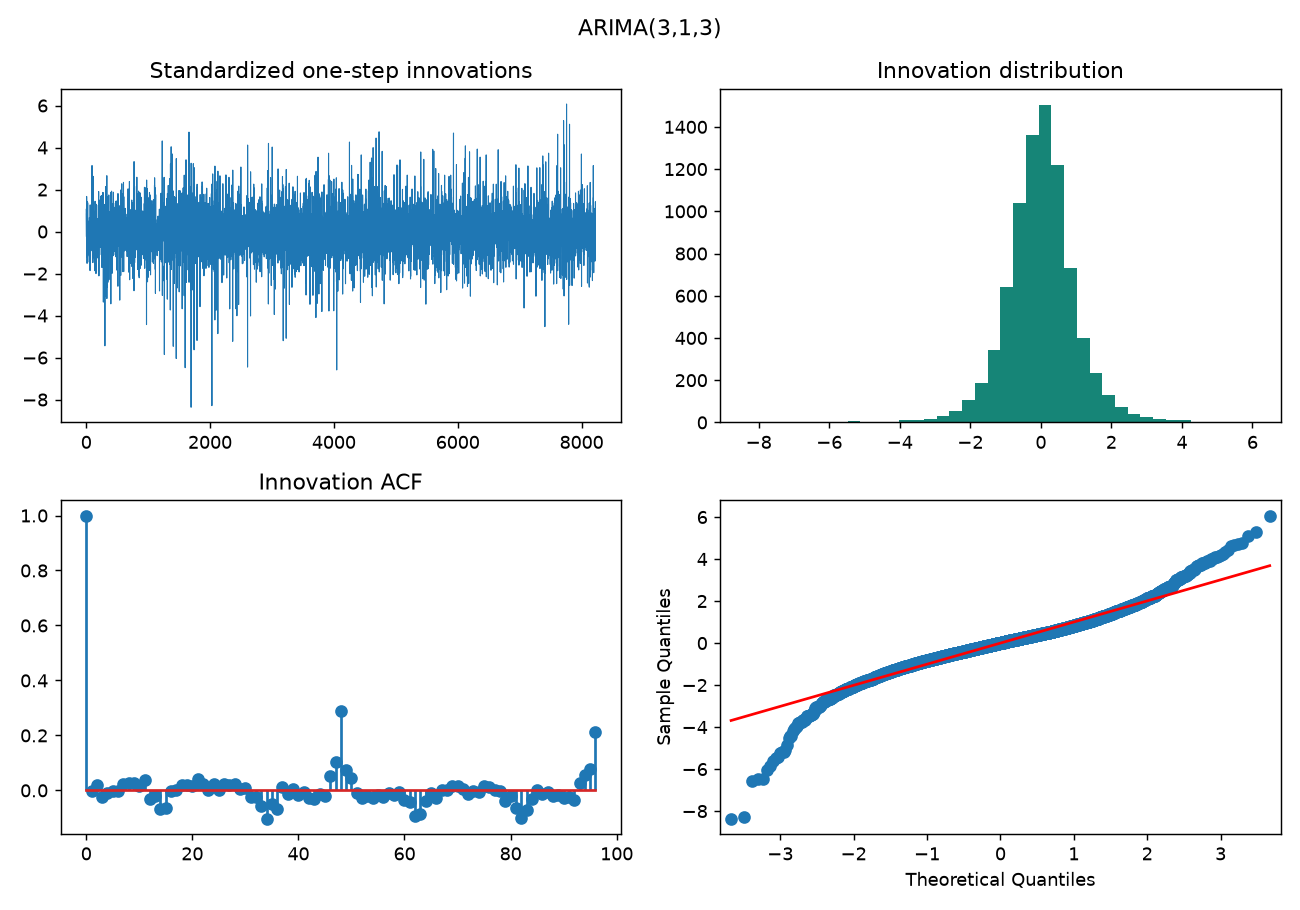

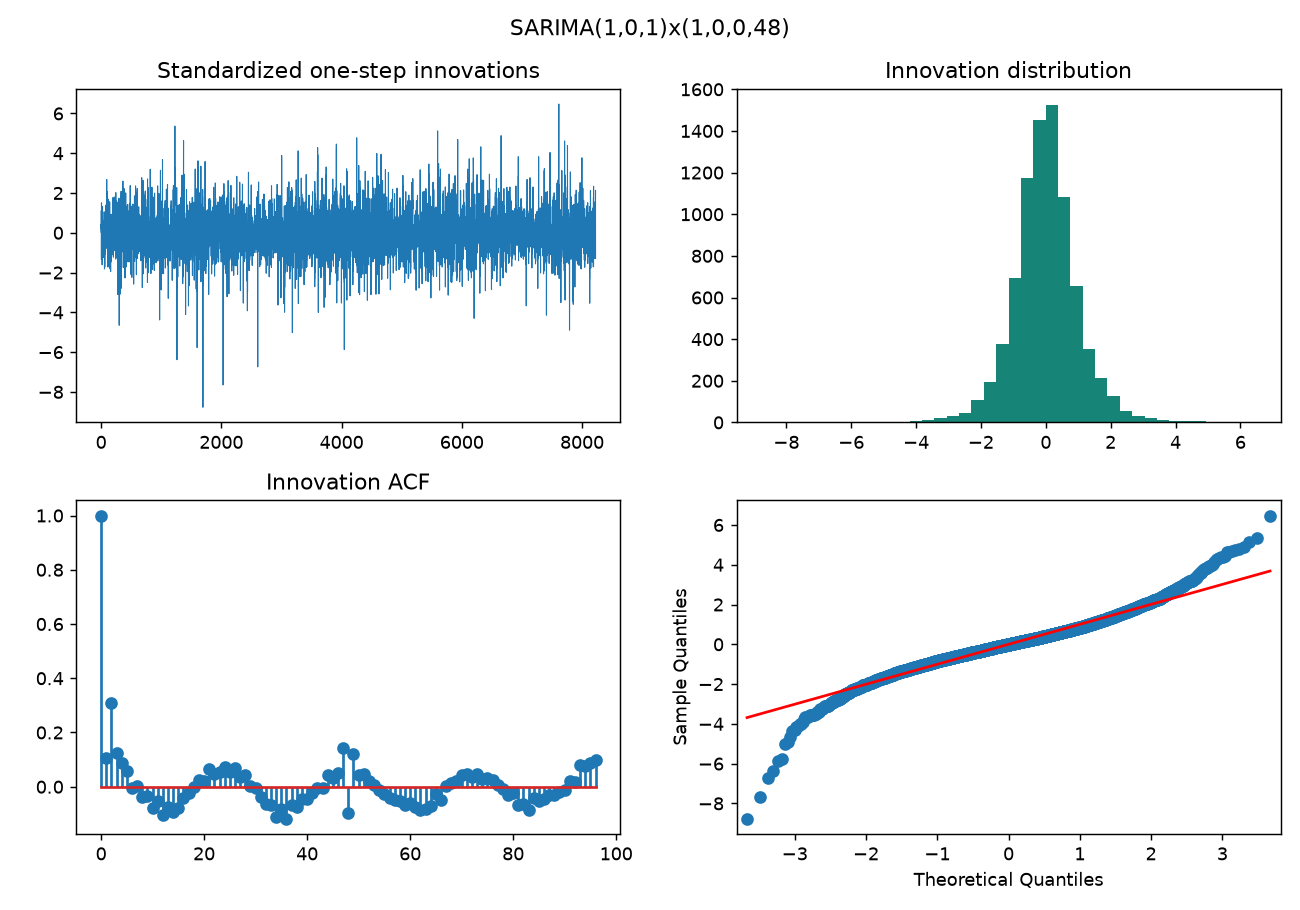

In [6]:
selection_path = ROOT / 'artifacts/runs' / STUDY_ID / 'selection' / 'selection_ledger.csv'
if selection_path.is_file():
    display(pd.read_csv(selection_path))
else:
    print('No selection ledger was recorded.')
for name in ('adf.csv', 'kpss.csv'):
    path = ROOT / 'artifacts/diagnostics' / name
    if path.is_file():
        display(pd.read_csv(path).head(30))
ljung_path = VALIDATION_RESIDUALS / 'ljung_box.csv'
if ljung_path.is_file():
    display(pd.read_csv(ljung_path))
else:
    print('No validation Ljung-Box table was recorded.')
for path in sorted(VALIDATION_RESIDUALS.glob('model_*_acf_pacf.csv')):
    print(path.name)
    display(pd.read_csv(path).head(20))
for path in sorted(VALIDATION_RESIDUALS.glob('model_*_diagnostics.png')):
    display(Image(filename=str(path)))

## 6. Chronological forecast comparisons and uncertainty

Each issue origin uses only observations whose interval end plus the assumed publication delay precedes that origin. Weekly parameter refits and causal filter updates forecast through the unobserved bridge onto a 48-slot UTC path. The test cannot change model or policy selections.

The common comparison excludes an origin if any competitor falls back. End-to-end metrics retain fallback behavior. Marginal interval coverage is not joint job-cost coverage, and parameter-estimation uncertainty is excluded.

In [7]:
validation_metrics = pd.read_csv(VALIDATION_RUN / 'forecast_metrics.csv')
test_metrics = pd.read_csv(TEST_RUN / 'forecast_metrics.csv')
display(validation_metrics)
display(test_metrics)
display(pd.read_csv(VALIDATION_RUN / 'forecast_common_metrics.csv'))
display(pd.read_csv(TEST_RUN / 'forecast_common_metrics.csv'))
for run in (VALIDATION_RUN, TEST_RUN):
    path = run / 'forecast_path_metrics.csv'
    if path.is_file():
        display(pd.read_csv(path))

,group_type,group,horizon,n,mae,rmse,mean_error,mase,coverage80,coverage95,width80,width95,interval_score80,interval_score95,fallback_origins,model_id
0,overall,all,1,17490,7.243163,9.925075,-0.125824,0.175739,0.842596,0.943110,25.657129,39.239193,36.251820,54.962613,0,"AR(7,0,0)"
1,season,winter,1,4321,7.215569,9.855999,-0.105974,0.166561,0.855820,0.953714,26.472778,40.486622,36.036655,54.697428,0,"AR(7,0,0)"
2,season,spring,1,4414,7.094732,9.550648,0.533035,0.158160,0.847984,0.947213,26.172180,40.026897,35.440108,51.049040,0,"AR(7,0,0)"
3,season,summer,1,4385,7.144948,10.138996,0.509797,0.175686,0.843558,0.936374,24.895575,38.074493,36.679878,58.422514,0,"AR(7,0,0)"
4,season,autumn,1,4370,7.518925,10.144800,-1.448746,0.202621,0.823112,0.935240,25.094566,38.378830,36.854932,55.706025,0,"AR(7,0,0)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345,overall,all,48,17490,47.482577,57.673540,1.692306,1.148227,0.773356,0.944425,140.984951,215.617877,197.035862,264.460890,0,calendar_mean
346,season,winter,48,4321,55.222600,65.045679,-1.306203,1.284875,0.716501,0.943532,147.875332,226.155805,216.715268,288.817522,0,calendar_mean
347,season,spring,48,4414,49.554607,58.590917,23.023040,1.101381,0.809470,0.979157,154.951204,236.977416,191.113481,248.735917,0,calendar_mean
348,season,summer,48,4385,35.099110,42.486088,17.721618,0.864553,0.898290,0.995211,137.380319,210.105066,150.974872,210.872369,0,calendar_mean


,group_type,group,horizon,n,mae,rmse,mean_error,mase,coverage80,coverage95,width80,width95,interval_score80,interval_score95,fallback_origins,model_id
0,overall,all,1,17473,6.786131,9.052596,0.031047,0.173441,0.832370,0.944715,23.619030,36.122192,32.943181,48.248296,0,"AR(7,0,0)"
1,season,winter,1,4273,6.653612,8.929901,-0.410092,0.166925,0.851861,0.953663,24.221773,37.044006,32.578561,48.350210,0,"AR(7,0,0)"
2,season,spring,1,4414,6.983086,9.318263,0.487133,0.161298,0.829406,0.937019,24.103197,36.862659,34.138107,49.706877,0,"AR(7,0,0)"
3,season,summer,1,4416,6.648719,8.843133,0.295334,0.170305,0.835598,0.948596,23.377474,35.752758,32.198690,46.763215,0,"AR(7,0,0)"
4,season,autumn,1,4370,6.855629,9.108520,-0.265351,0.195248,0.813043,0.939817,22.784733,34.846237,32.845080,48.176089,0,"AR(7,0,0)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,overall,all,48,17473,46.357988,56.165188,2.436381,1.188548,0.750472,0.937275,131.478565,201.079113,193.406467,260.147760,0,calendar_mean
221,season,winter,48,4273,50.332918,60.749257,-13.862579,1.260705,0.713082,0.925111,133.852151,204.709199,210.061466,270.033900,0,calendar_mean
222,season,spring,48,4414,46.612678,55.896371,18.307177,1.076706,0.787721,0.961939,143.371592,219.267928,188.980073,235.153729,0,calendar_mean
223,season,summer,48,4416,36.972799,44.108972,11.587654,0.942903,0.857337,0.997056,130.348994,199.351583,148.107492,199.843526,0,calendar_mean


,group_type,group,horizon,n,mae,rmse,mean_error,mase,coverage80,coverage95,width80,width95,interval_score80,interval_score95,fallback_origins,model_id,common_valid_origins
0,overall,all,1,15683,7.171785,9.791089,-0.116896,0.174708,0.845246,0.944717,25.618671,39.180378,35.885615,54.235978,0,"AR(7,0,0)",15685
1,season,winter,1,3649,7.184606,9.870049,-0.077489,0.167167,0.858865,0.952590,26.410776,40.391800,36.105990,55.459398,0,"AR(7,0,0)",15685
2,season,spring,1,4078,7.029233,9.462203,0.496719,0.157486,0.850172,0.948504,26.116028,39.941017,35.158918,50.504202,0,"AR(7,0,0)",15685
3,season,summer,1,3922,7.010170,9.783965,0.573244,0.172997,0.847527,0.940082,24.869987,38.035370,35.839475,56.311469,0,"AR(7,0,0)",15685
4,season,autumn,1,4034,7.461423,10.049772,-1.443831,0.200603,0.825731,0.938275,25.127277,38.428852,36.465756,54.883932,0,"AR(7,0,0)",15685
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345,overall,all,48,15654,47.734330,57.984785,1.814967,1.159929,0.767727,0.941548,140.277537,214.535980,198.822977,267.532386,0,calendar_mean,15685
346,season,winter,48,3649,54.752989,64.898107,-0.268621,1.286327,0.713346,0.939435,146.328139,223.789577,218.834548,295.053940,0,calendar_mean,15685
347,season,spring,48,4078,49.565699,58.527975,21.521186,1.106360,0.809220,0.978911,154.233056,235.879104,190.439356,248.254416,0,calendar_mean,15685
348,season,summer,48,3893,35.764683,43.233134,18.864550,0.883338,0.889545,0.994606,136.960913,209.463641,152.040755,210.327917,0,calendar_mean,15685


,group_type,group,horizon,n,mae,rmse,mean_error,mase,coverage80,coverage95,width80,width95,interval_score80,interval_score95,fallback_origins,model_id,common_valid_origins
0,overall,all,1,16465,6.812591,9.080595,0.024024,0.173835,0.831521,0.944671,23.645506,36.162678,33.004545,48.403022,0,"AR(7,0,0)",16465
1,season,winter,1,3937,6.691920,8.977827,-0.472562,0.166999,0.851918,0.954280,24.343809,37.230640,32.686866,48.783301,0,"AR(7,0,0)",16465
2,season,spring,1,4414,6.983086,9.318263,0.487133,0.161298,0.829406,0.937019,24.103197,36.862659,34.138107,49.706877,0,"AR(7,0,0)",16465
3,season,summer,1,3744,6.688243,8.869073,0.337985,0.170810,0.834135,0.949252,23.376303,35.750969,32.188312,46.730834,0,"AR(7,0,0)",16465
4,season,autumn,1,4370,6.855629,9.108520,-0.265351,0.195248,0.813043,0.939817,22.784733,34.846237,32.845080,48.176089,0,"AR(7,0,0)",16465
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,overall,all,48,16465,46.966620,56.866334,2.151417,1.202754,0.743274,0.933617,131.737347,201.474886,196.551531,264.148234,0,calendar_mean,16465
221,season,winter,48,3937,51.778095,62.205670,-16.088870,1.291961,0.697231,0.919482,134.511093,205.716965,216.323862,276.568543,0,calendar_mean,16465
222,season,spring,48,4414,46.612678,55.896371,18.307177,1.076706,0.787721,0.961939,143.371592,219.267928,188.980073,235.153729,0,calendar_mean,16465
223,season,summer,48,3744,36.801912,44.010598,12.855331,0.934897,0.858173,0.996528,130.804400,200.048067,148.717424,200.628308,0,calendar_mean,16465


,horizon,n_complete_paths,path_mae,path_rmse,prefix_mean_mae,prefix_mean_bias,units,model_id,comparison
0,1,17490,7.243163,9.925075,7.243163,-0.125824,gCO2/kWh,"AR(7,0,0)",end_to_end
1,4,17487,12.257850,17.185648,11.868513,-0.279567,gCO2/kWh,"AR(7,0,0)",end_to_end
2,12,17479,23.027152,30.989258,21.244378,-0.712632,gCO2/kWh,"AR(7,0,0)",end_to_end
3,24,17467,30.460770,39.206435,25.446539,-1.027911,gCO2/kWh,"AR(7,0,0)",end_to_end
4,48,17443,37.228254,46.698193,28.891237,-0.972024,gCO2/kWh,"AR(7,0,0)",end_to_end
...,...,...,...,...,...,...,...,...,...
135,1,15683,47.836835,58.129961,47.836835,2.327596,gCO2/kWh,calendar_mean,common_no_fallback
136,4,15680,47.841322,58.132631,47.643839,2.315191,gCO2/kWh,calendar_mean,common_no_fallback
137,12,15672,47.853924,58.142087,46.812002,2.288493,gCO2/kWh,calendar_mean,common_no_fallback
138,24,15660,47.854462,58.129264,45.238344,2.214167,gCO2/kWh,calendar_mean,common_no_fallback


,horizon,n_complete_paths,path_mae,path_rmse,prefix_mean_mae,prefix_mean_bias,units,model_id,comparison
0,1,17473,6.786131,9.052596,6.786131,0.031047,gCO2/kWh,"AR(7,0,0)",end_to_end
1,4,17473,11.784845,16.297367,11.417884,0.082617,gCO2/kWh,"AR(7,0,0)",end_to_end
2,12,17473,23.028357,30.971916,21.281686,0.274948,gCO2/kWh,"AR(7,0,0)",end_to_end
3,24,17473,30.960285,39.532494,25.815190,0.532957,gCO2/kWh,"AR(7,0,0)",end_to_end
4,48,17473,37.489943,46.351869,28.338957,0.950296,gCO2/kWh,"AR(7,0,0)",end_to_end
...,...,...,...,...,...,...,...,...,...
85,1,16465,47.057878,56.995898,47.057878,2.625805,gCO2/kWh,calendar_mean,common_no_fallback
86,4,16465,47.061408,57.000239,46.857955,2.592024,gCO2/kWh,calendar_mean,common_no_fallback
87,12,16465,47.068244,57.004808,45.768667,2.503792,gCO2/kWh,calendar_mean,common_no_fallback
88,24,16465,47.051241,56.976027,43.646891,2.386598,gCO2/kWh,calendar_mean,common_no_fallback


## 7. Primary and queue scheduling backtests

In [8]:
SOURCE_PATHS = {'validation_metrics': 'artifacts/runs/d2dee2d358735d7d/validation/forecast_metrics.csv', 'test_metrics': 'artifacts/runs/d2dee2d358735d7d/test/forecast_metrics.csv', 'primary_summary': 'artifacts/runs/d2dee2d358735d7d/test/single_job/primary_summary.csv', 'primary_bootstrap': 'artifacts/runs/d2dee2d358735d7d/test/single_job/primary_bootstrap.csv', 'primary_monthly': 'artifacts/runs/d2dee2d358735d7d/test/single_job/primary_monthly.csv', 'queue_summary': 'artifacts/runs/d2dee2d358735d7d/test/queue/queue_summary.csv'}
for name, relative_path in SOURCE_PATHS.items():
    path = ROOT / relative_path
    print(name, path.relative_to(ROOT))
    display(pd.read_csv(path))

validation_metrics artifacts\runs\d2dee2d358735d7d\validation\forecast_metrics.csv


,group_type,group,horizon,n,mae,rmse,mean_error,mase,coverage80,coverage95,width80,width95,interval_score80,interval_score95,fallback_origins,model_id
0,overall,all,1,17490,7.243163,9.925075,-0.125824,0.175739,0.842596,0.943110,25.657129,39.239193,36.251820,54.962613,0,"AR(7,0,0)"
1,season,winter,1,4321,7.215569,9.855999,-0.105974,0.166561,0.855820,0.953714,26.472778,40.486622,36.036655,54.697428,0,"AR(7,0,0)"
2,season,spring,1,4414,7.094732,9.550648,0.533035,0.158160,0.847984,0.947213,26.172180,40.026897,35.440108,51.049040,0,"AR(7,0,0)"
3,season,summer,1,4385,7.144948,10.138996,0.509797,0.175686,0.843558,0.936374,24.895575,38.074493,36.679878,58.422514,0,"AR(7,0,0)"
4,season,autumn,1,4370,7.518925,10.144800,-1.448746,0.202621,0.823112,0.935240,25.094566,38.378830,36.854932,55.706025,0,"AR(7,0,0)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345,overall,all,48,17490,47.482577,57.673540,1.692306,1.148227,0.773356,0.944425,140.984951,215.617877,197.035862,264.460890,0,calendar_mean
346,season,winter,48,4321,55.222600,65.045679,-1.306203,1.284875,0.716501,0.943532,147.875332,226.155805,216.715268,288.817522,0,calendar_mean
347,season,spring,48,4414,49.554607,58.590917,23.023040,1.101381,0.809470,0.979157,154.951204,236.977416,191.113481,248.735917,0,calendar_mean
348,season,summer,48,4385,35.099110,42.486088,17.721618,0.864553,0.898290,0.995211,137.380319,210.105066,150.974872,210.872369,0,calendar_mean


test_metrics artifacts\runs\d2dee2d358735d7d\test\forecast_metrics.csv


,group_type,group,horizon,n,mae,rmse,mean_error,mase,coverage80,coverage95,width80,width95,interval_score80,interval_score95,fallback_origins,model_id
0,overall,all,1,17473,6.786131,9.052596,0.031047,0.173441,0.832370,0.944715,23.619030,36.122192,32.943181,48.248296,0,"AR(7,0,0)"
1,season,winter,1,4273,6.653612,8.929901,-0.410092,0.166925,0.851861,0.953663,24.221773,37.044006,32.578561,48.350210,0,"AR(7,0,0)"
2,season,spring,1,4414,6.983086,9.318263,0.487133,0.161298,0.829406,0.937019,24.103197,36.862659,34.138107,49.706877,0,"AR(7,0,0)"
3,season,summer,1,4416,6.648719,8.843133,0.295334,0.170305,0.835598,0.948596,23.377474,35.752758,32.198690,46.763215,0,"AR(7,0,0)"
4,season,autumn,1,4370,6.855629,9.108520,-0.265351,0.195248,0.813043,0.939817,22.784733,34.846237,32.845080,48.176089,0,"AR(7,0,0)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,overall,all,48,17473,46.357988,56.165188,2.436381,1.188548,0.750472,0.937275,131.478565,201.079113,193.406467,260.147760,0,calendar_mean
221,season,winter,48,4273,50.332918,60.749257,-13.862579,1.260705,0.713082,0.925111,133.852151,204.709199,210.061466,270.033900,0,calendar_mean
222,season,spring,48,4414,46.612678,55.896371,18.307177,1.076706,0.787721,0.961939,143.371592,219.267928,188.980073,235.153729,0,calendar_mean
223,season,summer,48,4416,36.972799,44.108972,11.587654,0.942903,0.857337,0.997056,130.348994,199.351583,148.107492,199.843526,0,calendar_mean


primary_summary artifacts\runs\d2dee2d358735d7d\test\single_job\primary_summary.csv


...

,block_days,effective_block_days,n_resamples,paired_job_count,calendar_days,estimate_savings_grams,estimate_savings_grams_per_job,estimate_savings_pct,ci95_savings_grams_per_job_low,ci95_savings_grams_per_job_high,ci95_savings_pct_low,ci95_savings_pct_high,valid_resamples,is_primary_block,scenario_id,policy,model_id,validation_selected_model
0,3,3,2000,2913,365,44852.64,15.397405,12.414012,13.789046,16.945741,11.100342,13.648985,2000,False,duration_2h_slack_10h,forecast,calendar_mean,calendar_mean
1,7,7,2000,2913,365,44852.64,15.397405,12.414012,13.662495,17.092451,10.951237,13.828262,2000,True,duration_2h_slack_10h,forecast,calendar_mean,calendar_mean
2,14,14,2000,2913,365,44852.64,15.397405,12.414012,13.248618,17.331742,10.642997,14.069538,2000,False,duration_2h_slack_10h,forecast,calendar_mean,calendar_mean


primary_monthly artifacts\runs\d2dee2d358735d7d\test\single_job\primary_monthly.csv


,result_type,month_utc,scenario_id,duration_hours,slack_hours,policy,model_id,metric_scope,lead_slots,n_eligible_jobs,...,mase,interval_n,interval_coverage80,interval_coverage95,window_cost_mae_grams,window_cost_n,candidate_rank_spearman,candidate_rank_n,validation_selected_model,selected_for_deployment
0,scheduling,2025-01,duration_0.5h_slack_0h,0.5,0.0,earliest,NaN,scenario,NaN,248,...,NaN,0,NaN,NaN,NaN,0,NaN,0,calendar_mean,False
1,scheduling,2025-01,duration_0.5h_slack_0h,0.5,0.0,seeded_random,NaN,scenario,NaN,248,...,NaN,0,NaN,NaN,NaN,0,NaN,0,calendar_mean,False
2,scheduling,2025-01,duration_0.5h_slack_0h,0.5,0.0,oracle,oracle,scenario,NaN,248,...,NaN,0,NaN,NaN,NaN,0,NaN,0,calendar_mean,False
3,scheduling,2025-01,duration_0.5h_slack_0h,0.5,0.0,forecast,"AR(7,0,0)",scenario,NaN,248,...,NaN,0,NaN,NaN,NaN,0,NaN,0,calendar_mean,False
4,scheduling,2025-01,duration_0.5h_slack_0h,0.5,0.0,forecast,"ARIMA(3,1,3)",scenario,NaN,248,...,NaN,0,NaN,NaN,NaN,0,NaN,0,calendar_mean,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3019,scheduling,2025-12,duration_4h_slack_20h,4.0,20.0,forecast,"SARIMA(1,0,1)x(1,0,0,48)",scenario,NaN,241,...,NaN,0,NaN,NaN,NaN,0,NaN,0,calendar_mean,False
3020,scheduling,2025-12,duration_4h_slack_20h,4.0,20.0,forecast,calendar_mean,scenario,NaN,241,...,NaN,0,NaN,NaN,NaN,0,NaN,0,calendar_mean,True
3021,scheduling,2025-12,duration_4h_slack_20h,4.0,20.0,forecast,daily_naive,scenario,NaN,241,...,NaN,0,NaN,NaN,NaN,0,NaN,0,calendar_mean,False
3022,scheduling,2025-12,duration_4h_slack_20h,4.0,20.0,forecast,persistence,scenario,NaN,241,...,NaN,0,NaN,NaN,NaN,0,NaN,0,calendar_mean,False


queue_summary artifacts\runs\d2dee2d358735d7d\test\queue\queue_summary.csv


,offered_load,seed,slack_hours,policy,offered_jobs,completed_jobs,rejected_jobs,rejection_rate,deadline_misses,total_completed_energy_kwh,...,fixed_work_comparison,whole_offered_trace_completed,interpretation,waiting_median_hours,waiting_p95_hours,fallback_rate,actual_discretized_offered_load,facility_idle_power_kw_assumed,secondary_facility_grams,secondary_facility_energy_kwh
0,0.30,1729,6,earliest,1411,1404,7,0.004961,0,1268.64,...,False,False,descriptive completion intersection; service d...,0.0,3.0,0.0,0.303425,0.08,240418.224,1855.872
1,0.30,1729,6,selected,1411,1380,31,0.021970,0,1238.40,...,False,False,descriptive completion intersection; service d...,4.0,6.0,0.0,0.303425,0.08,228199.728,1832.448
2,0.30,1729,6,strongest_simple,1411,1404,7,0.004961,0,1268.64,...,False,False,descriptive completion intersection; service d...,0.0,3.0,0.0,0.303425,0.08,240418.224,1855.872
3,0.30,1729,12,earliest,1411,1410,1,0.000709,0,1275.36,...,False,False,descriptive completion intersection; service d...,0.0,3.5,0.0,0.303425,0.08,241155.888,1861.248
4,0.30,1729,12,selected,1411,1404,7,0.004961,0,1268.64,...,False,False,descriptive completion intersection; service d...,8.0,12.0,0.0,0.303425,0.08,228501.744,1857.600
5,0.30,1729,12,strongest_simple,1411,1410,1,0.000709,0,1275.36,...,False,False,descriptive completion intersection; service d...,0.0,3.5,0.0,0.303425,0.08,241155.888,1861.248
6,0.30,2718,6,earliest,1324,1317,7,0.005287,0,1194.24,...,False,False,descriptive completion intersection; service d...,0.0,3.0,0.0,0.285502,0.08,229115.952,1796.352
7,0.30,2718,6,selected,1324,1294,30,0.022659,0,1161.60,...,False,False,descriptive completion intersection; service d...,4.0,6.0,0.0,0.285502,0.08,219531.504,1771.008
8,0.30,2718,6,strongest_simple,1324,1317,7,0.005287,0,1194.24,...,False,False,descriptive completion intersection; service d...,0.0,3.0,0.0,0.285502,0.08,229115.952,1796.352
9,0.30,2718,12,earliest,1324,1324,0,0.000000,0,1200.48,...,False,True,descriptive completion intersection; service d...,0.0,3.5,0.0,0.285502,0.08,229565.808,1801.344


In [9]:
display(pd.DataFrame([{
    'primary_jobs': RESULTS['primary_jobs'],
    'deadline_misses': RESULTS['primary_deadline_misses'],
    'modeled_savings_pct': RESULTS['primary_savings_pct'],
    'ci95_pct': RESULTS['primary_ci95_pct'],
    'interpretation': RESULTS['h3_interpretation'],
}]))
display(pd.read_csv(TEST_RUN / 'forecast_loss_bootstrap.csv'))
display(pd.read_csv(TEST_RUN / 'single_job/versus_simple_bootstrap.csv'))

,primary_jobs,deadline_misses,modeled_savings_pct,ci95_pct,interpretation
0,2913,0,12.414012,"[10.951237233041386, 13.82826208206238]",No classical deployment was selected; selected...


,block_days,effective_block_days,n_resamples,paired_origin_count,calendar_days,estimate_loss_reduction_gco2_per_kwh,estimate_loss_reduction_gco2_per_kwh_per_origin,estimate_loss_reduction_pct,ci95_loss_reduction_gco2_per_kwh_per_origin_low,ci95_loss_reduction_gco2_per_kwh_per_origin_high,ci95_loss_reduction_pct_low,ci95_loss_reduction_pct_high,valid_resamples,classical,baseline,interpretation
0,3,3,2000,16465,365,76877.156051,4.669126,16.032982,3.909772,5.398000,13.670098,18.386734,2000,"SARIMA(1,0,1)x(1,0,0,48)",persistence,Secondary descriptive paired equal-horizon MAE...
1,7,7,2000,16465,365,76877.156051,4.669126,16.032982,3.840883,5.502599,13.372741,18.702261,2000,"SARIMA(1,0,1)x(1,0,0,48)",persistence,Secondary descriptive paired equal-horizon MAE...
2,14,14,2000,16465,365,76877.156051,4.669126,16.032982,3.769318,5.458936,13.270247,18.729043,2000,"SARIMA(1,0,1)x(1,0,0,48)",persistence,Secondary descriptive paired equal-horizon MAE...


,block_days,effective_block_days,n_resamples,paired_job_count,calendar_days,estimate_savings_grams,estimate_savings_grams_per_job,estimate_savings_pct,ci95_savings_grams_per_job_low,ci95_savings_grams_per_job_high,ci95_savings_pct_low,ci95_savings_pct_high,valid_resamples
0,3,3,2000,2913,365,44852.64,15.397405,12.414012,13.789046,16.945741,11.100342,13.648985,2000
1,7,7,2000,2913,365,44852.64,15.397405,12.414012,13.662495,17.092451,10.951237,13.828262,2000
2,14,14,2000,2913,365,44852.64,15.397405,12.414012,13.248618,17.331742,10.642997,14.069538,2000


The default isolated cases use 0.4 kW allocated IT power and PUE 1.2, so a two-hour job consumes a modeled 0.96 kWh. Starts minimize the energy-weighted whole-job path, not its lowest point. These overlapping cases are correlated counterfactuals, not one executable annual trace.

Queue policies see only arrivals and immutable prior reservations. When accepted job sets differ, matched-job emissions comparisons are descriptive post-policy intersections. Rejected work is not carbon saved.

## 8. Sensitivities, negative outcomes, limitations, and deployment

In [10]:
from gridshift.live import verify_deployment_fixture
display(verify_deployment_fixture(ROOT, CONFIG))
for name in ('sensitivity_summary.csv', 'energy_profile_sensitivity.csv', 'outage_state_replay.csv'):
    display(pd.read_csv(ROOT / 'artifacts/sensitivities' / name))
for path in sorted(VALIDATION_RESIDUALS.glob('model_*_job_uncertainty.json')):
    display(json.loads(path.read_text()))
display(pd.DataFrame({'limitation': RESULTS.get('limitations', [])}))
manifest = json.loads((ROOT / 'data/manifest.json').read_text(encoding='utf-8'))
print('Normalized data hash:', manifest.get('normalized_hash'))
print('This notebook reports only stored outcomes. A missing row remains missing.')
print('No model fitting, network request, or workload execution occurs in this notebook.')

{'verified': True,
 'model_id': 'calendar_mean',
 'origin': '2026-01-01 00:00:00+00:00',
 'max_mean_absolute_difference': 0.0,
 'observation_state': 'fresh',
 'realized_result': 'not scored'}

,month,variant,model_id,result_type,month_utc,scenario_id,duration_hours,slack_hours,policy,metric_scope,...,window_cost_n,candidate_rank_spearman,candidate_rank_n,validation_selected_model,selected_for_deployment,interval_method,validation_fallback_rate,validation_mean_realized_grams,selection_basis,selection_metadata
0,1,default,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.633550,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN
1,1,delay_0min,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.634963,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN
2,1,delay_60min,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.629386,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN
3,1,window_90days,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.641610,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN
4,1,window_365days,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.622739,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN
5,1,native_missing,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.633550,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN
6,4,default,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.301236,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN
7,4,delay_0min,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.308995,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN
8,4,delay_60min,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.299591,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN
9,4,window_90days,"SARIMA(1,0,1)x(1,0,0,48)",scheduling,NaN,duration_2h_slack_10h,2.0,10.0,forecast,scenario,...,357.0,0.300089,17.0,"SARIMA(1,0,1)x(1,0,0,48)",True,NaN,NaN,NaN,NaN,NaN


,month,origin,profile,energy_kwh,chosen_start,earliest_grams,selected_grams,oracle_grams,predicted_grams,scope
0,1,2024-01-01 00:00:00+00:00,constant,0.96,2024-01-01 00:00:00+00:00,62.64,62.64,45.84,61.789814,Descriptive quarterly validation episodes
1,1,2024-01-01 00:00:00+00:00,nonconstant,0.96,2024-01-01 00:00:00+00:00,63.72,63.72,45.96,62.231620,Descriptive quarterly validation episodes
2,1,2024-01-01 03:00:00+00:00,constant,0.96,2024-01-01 03:00:00+00:00,57.12,57.12,45.84,64.153063,Descriptive quarterly validation episodes
3,1,2024-01-01 03:00:00+00:00,nonconstant,0.96,2024-01-01 03:00:00+00:00,56.64,56.64,45.96,64.485026,Descriptive quarterly validation episodes
4,1,2024-01-01 06:00:00+00:00,constant,0.96,2024-01-01 06:00:00+00:00,56.16,56.16,45.84,57.104572,Descriptive quarterly validation episodes
...,...,...,...,...,...,...,...,...,...,...
131,10,2024-10-02 18:00:00+00:00,nonconstant,0.96,2024-10-03 01:00:00+00:00,156.36,121.68,101.16,123.761426,Descriptive quarterly validation episodes
132,10,2024-10-02 21:00:00+00:00,constant,0.96,2024-10-03 01:00:00+00:00,103.44,120.48,101.04,115.837679,Descriptive quarterly validation episodes
133,10,2024-10-02 21:00:00+00:00,nonconstant,0.96,2024-10-03 01:00:00+00:00,102.12,121.68,101.16,115.800791,Descriptive quarterly validation episodes
134,10,2024-10-03 00:00:00+00:00,constant,0.96,2024-10-03 00:30:00+00:00,118.56,117.84,117.84,105.723076,Descriptive quarterly validation episodes


,origin,status,recommendation_enabled,last_observation,age_hours,injected_outage_hours,fallback_start,fallback_finish,deadline,carbon_estimate,scope
0,2024-01-01 00:00:00+00:00,stale,False,2023-12-31 18:00:00+00:00,5.5,6,2024-01-01 00:00:00+00:00,2024-01-01 02:00:00+00:00,2024-01-01 12:00:00+00:00,NaN,Operational state replay using only eligible v...
1,2024-04-01 00:00:00+00:00,stale,False,2024-03-31 18:00:00+00:00,5.5,6,2024-04-01 00:00:00+00:00,2024-04-01 02:00:00+00:00,2024-04-01 12:00:00+00:00,NaN,Operational state replay using only eligible v...
2,2024-07-01 00:00:00+00:00,stale,False,2024-06-30 18:00:00+00:00,5.5,6,2024-07-01 00:00:00+00:00,2024-07-01 02:00:00+00:00,2024-07-01 12:00:00+00:00,NaN,Operational state replay using only eligible v...
3,2024-10-01 00:00:00+00:00,stale,False,2024-09-30 18:00:00+00:00,5.5,6,2024-10-01 00:00:00+00:00,2024-10-01 02:00:00+00:00,2024-10-01 12:00:00+00:00,NaN,Operational state replay using only eligible v...


{'chosen_start': '2024-12-01 00:00:00+00:00',
 'duration_hours': 2,
 'energy_kwh': 0.96,
 'lower80': 66.00382127440898,
 'lower95': 55.79648289102184,
 'mean_grams': 85.93117645469968,
 'median_grams': 85.62289184370843,
 'method': 'Joint conditional state-space paths with fixed fitted parameters',
 'model_id': 'AR(7,0,0)',
 'origin': '2024-12-01 00:00:00+00:00',
 'scope': 'Representative validation conditional joint-path example; not calibrated job-cost coverage',
 'simulations': 1000,
 'std_grams': 15.881264029889245,
 'upper80': 107.38121777854614,
 'upper95': 116.77825898628033}

...

{'chosen_start': '2024-12-01 00:00:00+00:00',
 'duration_hours': 2,
 'energy_kwh': 0.96,
 'lower80': 68.48228629437871,
 'lower95': 57.3221396040885,
 'mean_grams': 87.65833924627492,
 'median_grams': 87.53763825927251,
 'method': 'Joint conditional state-space paths with fixed fitted parameters',
 'model_id': 'ARMA(3,0,2)',
 'origin': '2024-12-01 00:00:00+00:00',
 'scope': 'Representative validation conditional joint-path example; not calibrated job-cost coverage',
 'simulations': 1000,
 'std_grams': 15.043444587229821,
 'upper80': 106.48314937299251,
 'upper95': 117.07793354378288}

{'chosen_start': '2024-12-01 00:00:00+00:00',
 'duration_hours': 2,
 'energy_kwh': 0.96,
 'lower80': 66.50678765936539,
 'lower95': 57.50008673265771,
 'mean_grams': 86.15302045223257,
 'median_grams': 86.56683696869523,
 'method': 'Joint conditional state-space paths with fixed fitted parameters',
 'model_id': 'ARIMA(3,1,3)',
 'origin': '2024-12-01 00:00:00+00:00',
 'scope': 'Representative validation conditional joint-path example; not calibrated job-cost coverage',
 'simulations': 1000,
 'std_grams': 15.256971316682643,
 'upper80': 105.72641781268663,
 'upper95': 115.64755508261145}

{'chosen_start': '2024-12-01 00:00:00+00:00',
 'duration_hours': 2,
 'energy_kwh': 0.96,
 'lower80': 73.94348672688412,
 'lower95': 66.02977651375599,
 'mean_grams': 88.1027456834389,
 'median_grams': 87.93517570059399,
 'method': 'Joint conditional state-space paths with fixed fitted parameters',
 'model_id': 'SARIMA(1,0,1)x(1,0,0,48)',
 'origin': '2024-12-01 00:00:00+00:00',
 'scope': 'Representative validation conditional joint-path example; not calibrated job-cost coverage',
 'simulations': 1000,
 'std_grams': 11.298885836902034,
 'upper80': 102.68933915134761,
 'upper95': 109.9735548348609}

,limitation
0,Retrospective NESO estimated actuals have no v...
1,Thirty-minute publication delay is an assumed ...
2,"Power, PUE, known durations, and arrivals are ..."
3,Costs are modeled intensity-weighted operation...
4,National GB intensity is a proxy for a hypothe...
5,Predictive intervals condition on fitted param...
6,Queue completion intersections are descriptive...
7,"Net computing overhead, marginal emissions, an..."
8,The untouched test covers 2025 only. No post-t...
9,Local packaging and runtime verification do no...


Normalized data hash: f57548d5bc197f884b5b35bb84faaaadcb38b7b46dc3e8c925a150b8ea5a5a1e
This notebook reports only stored outcomes. A missing row remains missing.
No model fitting, network request, or workload execution occurs in this notebook.
